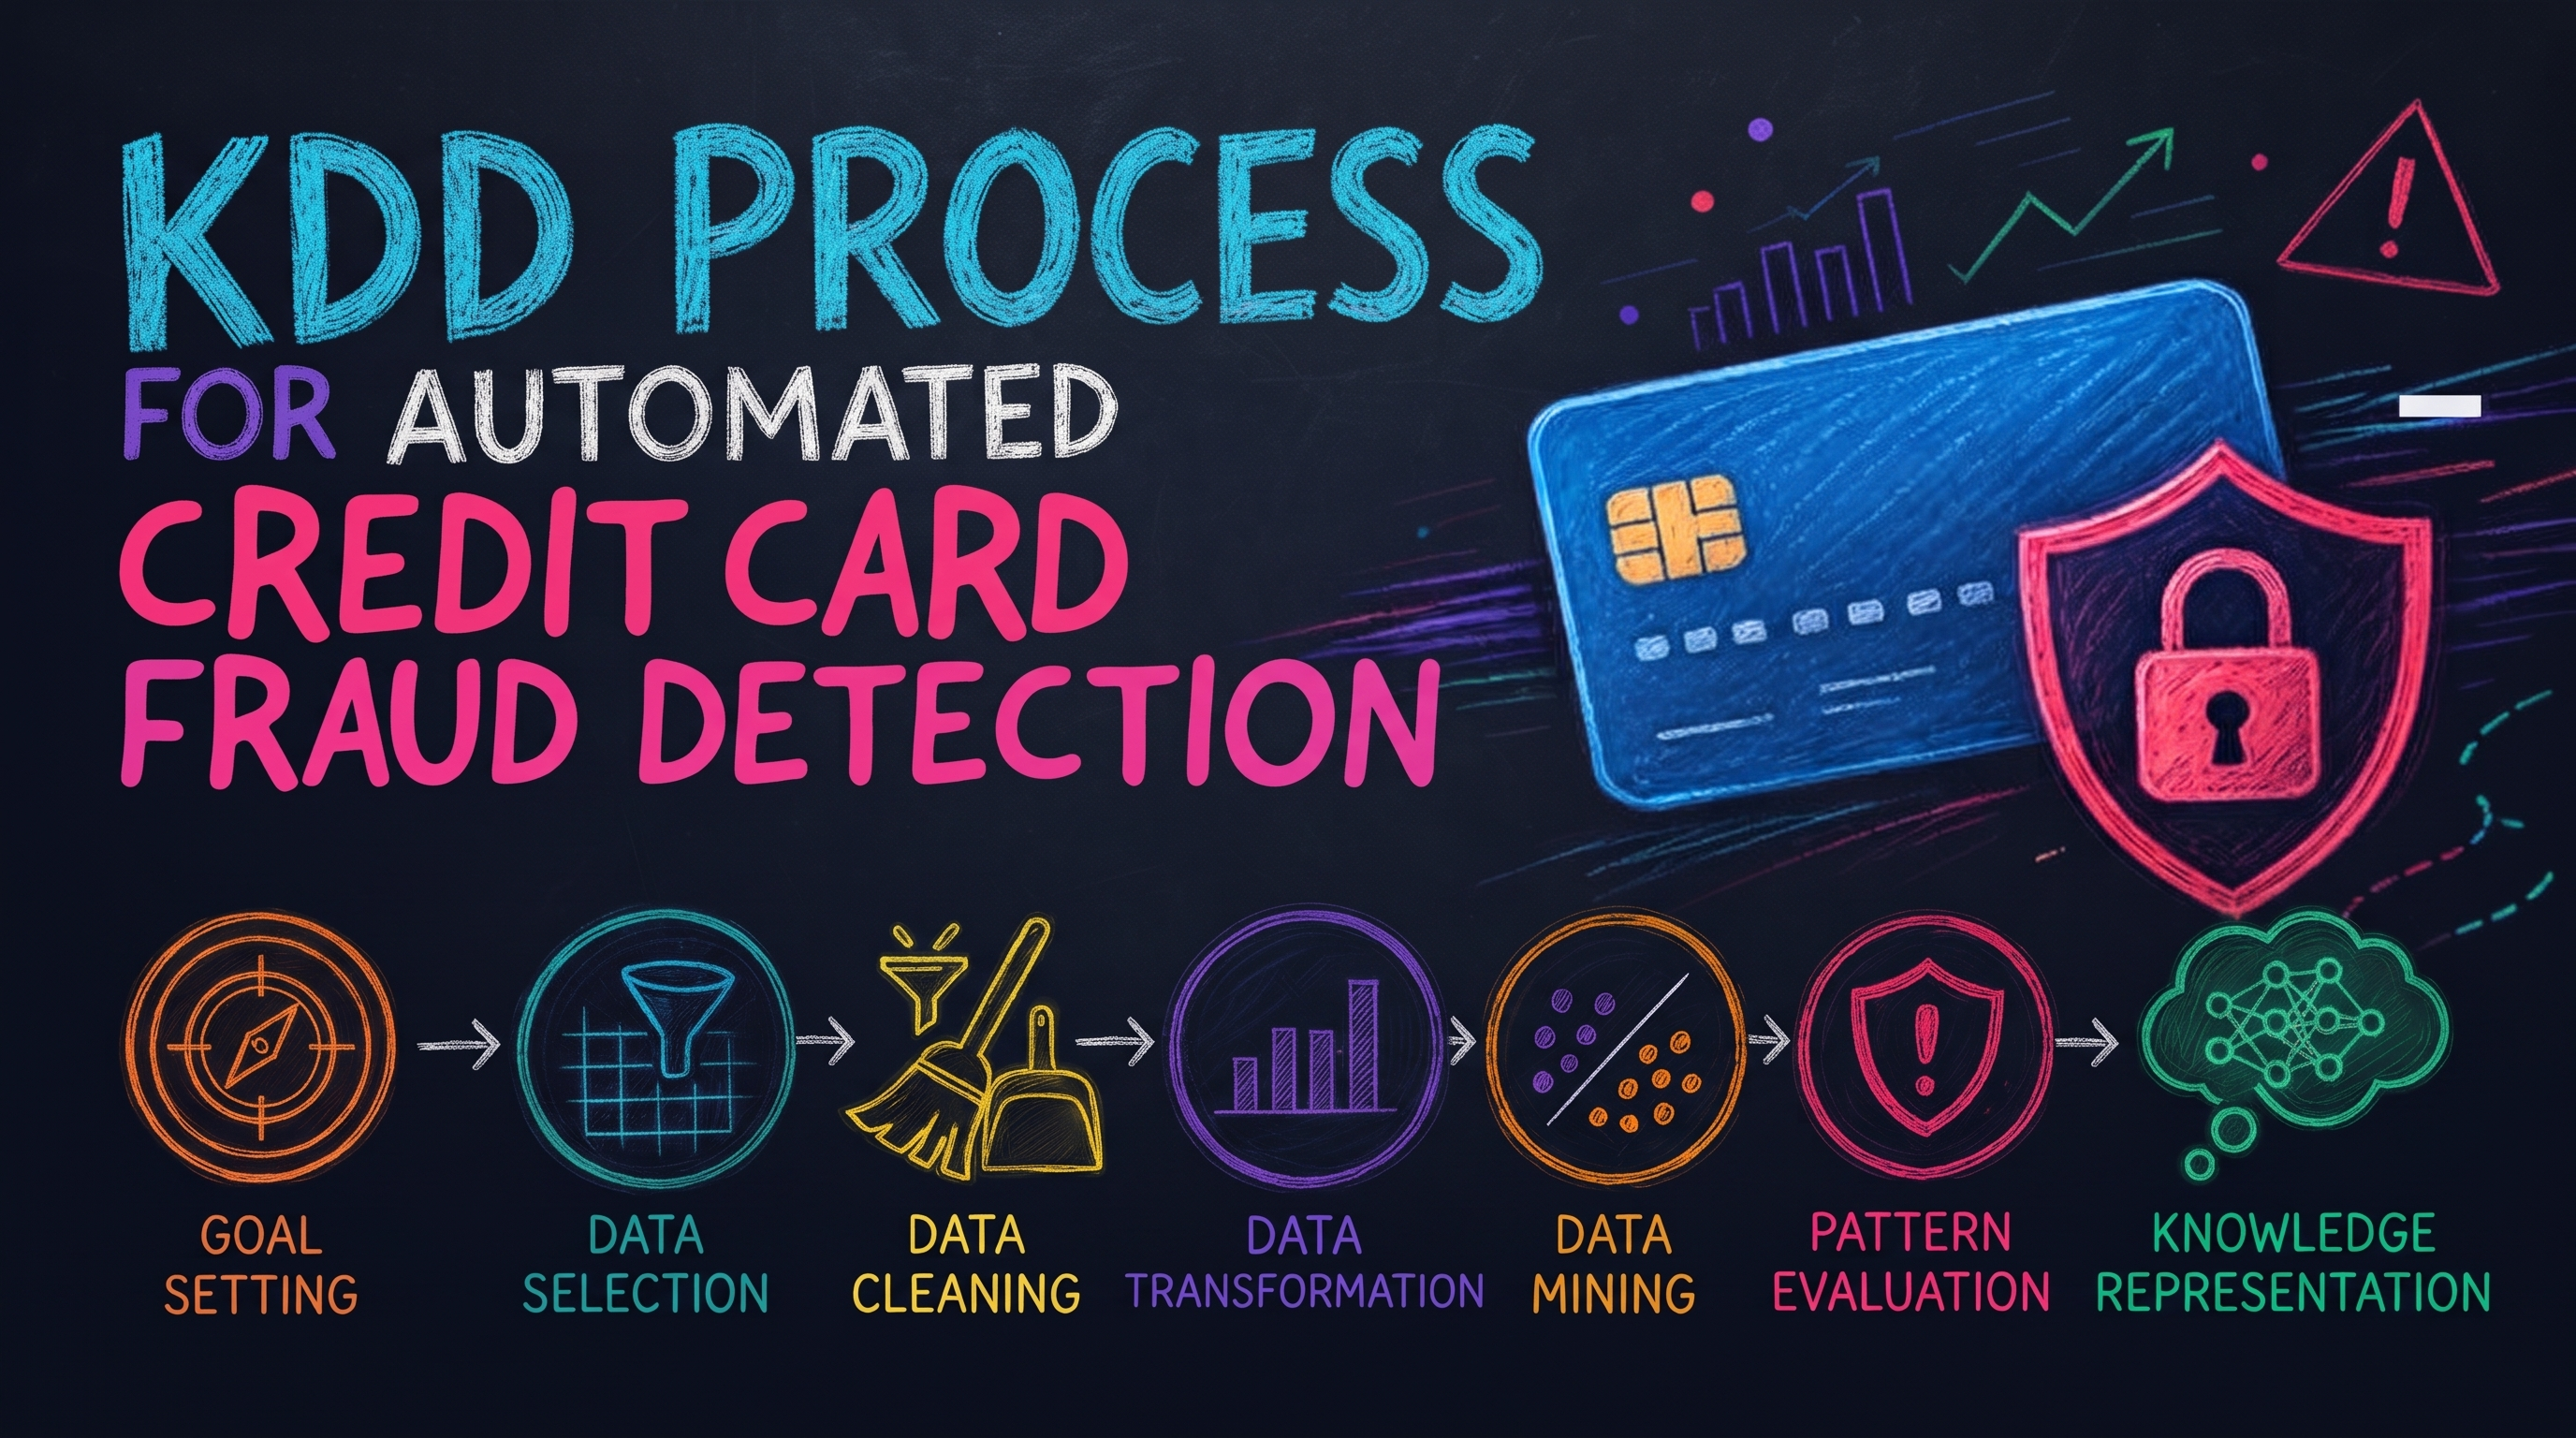

|   |   |
| :--- | :--- |
| **Institución** | Universidad de Guadalajara — Centro Universitario de Guadalajara (CUGDL) |
| **Plan de Estudios** | Licenciatura en Inteligencia Artificial y Ciencia de Datos |
| **Materia** | Data Mining & Knowledge Discovery |
| **Profesora Titular** | **Mtra. Milagros Contreras Elizalde** |
| **Alumno** | Roberto Alejandro Chagra Martínez (Código: `208447128`) |
| **Fecha de Entrega** | 23 de Noviembre de 2026 |
| **Fuente Oficial de Datos** | [Kaggle: Credit Card Fraud Detection Dataset 2026](https://www.kaggle.com/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/data) (Mohan Krishna Thalla) |
| **Base de Datos** | `credit_card_fraud_detection_2026.csv` (`100,000` transacciones $\times$ `43` atributos originales) |

---
---

## Etapa 0 KDD: Configuración del Entorno, Importación de Librerías y Definición de Rutas

En esta etapa preliminar se centralizan todas las dependencias tecnológicas, la configuración cromática institucional y la arquitectura de directorios del proyecto, garantizando plena portabilidad y reproducibilidad tanto en entornos locales como en **Google Colab**.

### Objetivos y Alcance de la Etapa 0:
1. **Importación Concentrada de Librerías:** Centralizar todos los módulos analíticos, estadísticos y de Machine Learning en un único punto de entrada (`pandas`, `numpy`, `scikit-learn`, `imblearn`, `xgboost`, `scipy`, `matplotlib`, `seaborn`).
2. **Definición de Paleta Institucional (Cyber Dark Neón):** Estandarizar las constantes cromáticas (`CYBER_DARK`, `CYBER_BLUE`, `CYBER_CYAN`, `CYBER_MAGENTA`, `CYBER_PURPLE`, `CYBER_GREEN`, `CYBER_AMBER`) y la configuración tipográfica de gráficos de alta resolución.
3. **Gestión de Rutas y Compatibilidad con Google Colab:** Detectar automáticamente el entorno de ejecución, definir las rutas para artefactos (`results/`, `results/graficas/`), y crear los directorios automáticamente si no existen (`mkdir(parents=True, exist_ok=True)`).
4. **Declaración de Ruta del Dataset:** Establecer la ubicación oficial de la base de datos transaccional (`credit_card_fraud_detection_2026.csv`) sin ejecutar descargas intrusivas en esta celda.


In [ ]:
# @title ETAPA 0 KDD: CONFIGURACIÓN GLOBAL, IMPORTACIONES Y RUTAS DE TRABAJO

# 0.0 Parche de Compatibilidad para Python 3.13 (Módulo cgi eliminado)
import sys
from types import ModuleType
if 'cgi' not in sys.modules:
    cgi_mock = ModuleType('cgi')
    def parse_header(line):
        parts = [p.strip() for p in line.split(';')]
        key = parts[0]
        params = {}
        for p in parts[1:]:
            if '=' in p:
                k, v = p.split('=', 1)
                params[k.strip()] = v.strip('" ')
        return key, params
    cgi_mock.parse_header = parse_header
    sys.modules['cgi'] = cgi_mock

# 0.1 Importación Concentrada de Librerías y Módulos Analíticos
import os
import warnings
import json
import io
import time
import shutil
from pathlib import Path

# Librerías Científicas y Manipulación de Datos
import numpy as np
import pandas as pd
import scipy.stats as stats

# Visualización y Estilos Gráficos
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Modelado y Preprocesamiento (scikit-learn)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import chi2
from sklearn.ensemble import (
    IsolationForest,
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.tree import (
    DecisionTreeClassifier,
    export_text,
    plot_tree
)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Métricas de Desempeño y Validación Cruzada
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Algoritmos de Balanceo Sintético (SMOTE)
from imblearn.over_sampling import SMOTE

# Modelos Avanzados de Gradient Boosting (opcional / alternativo)
try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False

# Supresión de advertencias innecesarias en ejecución interactiva
warnings.filterwarnings('ignore')

# Definir variables de entorno de trabajo faltantes
IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content') if IN_COLAB else Path('.')

print('[OK] 0.1 Librerías analíticas e importaciones cargadas exitosamente.')


# 0.2 Definición de la Paleta de Colores Oficial (Cyber Dark Neón) y Estilos

# Constantes cromáticas coherentes con el Reporte Oficial y Portada UdeG
CYBER_BG      = '#060b19'   # Fondo oscuro principal
CYBER_PANEL   = '#0d1527'   # Fondo de contenedores y paneles
CYBER_DARK    = '#0f172a'   # Carbón oscuro para títulos y bordes
CYBER_BLUE    = '#0284c7'   # Azul corporativo / primario
CYBER_CYAN    = '#00f0ff'   # Cian Neón brillante
CYBER_MAGENTA = '#ff2a85'   # Magenta / Rosa Neón (Alertas / Fraude)
CYBER_PURPLE  = '#7c3aed'   # Púrpura Neón eléctrico
CYBER_GREEN   = '#10b981'   # Verde Esmeralda (Legítimo / Reglas)
CYBER_AMBER   = '#f59e0b'   # Ámbar / Alerta temprana

# Configuración global de Matplotlib y Seaborn
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.size'] = 10
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['grid.color'] = '#e2e8f0'
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titleweight'] = 'bold'


# 0.3 Creación Automática de Directorios


# Creación automática de directorios de resultados si no existen
results_candidatos = [
    Path('results'),
    Path('../results'),
    Path('../../results'),
    BASE_DIR / 'results'
]
RESULTS_DIR = next((p for p in results_candidatos if p.exists()), BASE_DIR / 'results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

GRAFICAS_DIR = RESULTS_DIR / 'graficas'
GRAFICAS_DIR.mkdir(parents=True, exist_ok=True)

# Variable de compatibilidad histórica para celdas posteriores
out_dir = RESULTS_DIR

print(f'[RUTAS] Directorio de resultados: {RESULTS_DIR.resolve()}')
print(f'[RUTAS] Directorio de gráficas:   {GRAFICAS_DIR.resolve()}')

# 0.4 Definición de Rutas y Descarga Condicional desde Kaggle si no Existe

# Creación automática de la carpeta Datasets/ si no existe
DATA_DIR = BASE_DIR / 'Datasets' if IN_COLAB else Path('Datasets')
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Rutas estándar candidatas donde puede alojarse el archivo CSV
dataset_candidatos = [
    Path('Datasets/credit_card_fraud_detection_2026.csv'),
    Path('../Datasets/credit_card_fraud_detection_2026.csv'),
    Path('../../Datasets/credit_card_fraud_detection_2026.csv'),
    BASE_DIR / 'Datasets' / 'credit_card_fraud_detection_2026.csv',
    BASE_DIR / 'credit_card_fraud_detection_2026.csv',
    Path('credit_card_fraud_detection_2026.csv'),
    Path('credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv')
]

# Ruta predeterminada y comprobación de existencia
DATA_PATH = DATA_DIR / 'credit_card_fraud_detection_2026.csv'
csv_path = next((p for p in dataset_candidatos if p.exists()), DATA_PATH)

print(f'[DATOS] Carpeta oficial de datos: {DATA_DIR.resolve()}')
print(f'[DATOS] Ruta asignada al dataset: {csv_path.resolve()}')

# Si el dataset NO existe, NO SE DETIENE: se descarga directamente de Kaggle con opendatasets
if not csv_path.exists():
    print(f'[INFO] Archivo no detectado en el entorno local/Colab.')
    print('[INFO] Iniciando descarga directa desde Kaggle con opendatasets...')

    # 1. Instalación de opendatasets si no estuviese presente
    try:
        import opendatasets as od
    except ImportError:
        print('[INFO] Instalando librería opendatasets...')
        try:
            get_ipython().system('pip install -q opendatasets')
        except Exception:
            import subprocess
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'opendatasets'])
        import opendatasets as od

    # 2. Descarga oficial de Kaggle
    kaggle_url = 'https://www.kaggle.com/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026'
    orig_path = Path('credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv')
    if not orig_path.exists():
        print('[INFO] Iniciando descarga directa desde Kaggle...')
        od.download(kaggle_url)

    # 3. Mover el archivo descargado a la ruta asignada
    if orig_path.exists():
        DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
        if str(orig_path.resolve()) != str(DATA_PATH.resolve()):
            shutil.copy2(str(orig_path), str(DATA_PATH))
        dest_raiz = Path('credit_card_fraud_detection_2026.csv')
        if not dest_raiz.exists():
            shutil.copy2(str(orig_path), str(dest_raiz))
        csv_path = DATA_PATH
        print(f'[OK] ¡Archivo del dataset listo en "{csv_path}" para ser procesado!')
    else:
        print(f'[AVISO] No se pudo encontrar el archivo descargado en {orig_path}.')
else:
    print(f'[OK] Archivo del dataset localizado en: {csv_path.name} (descarga de Kaggle omitida).')

[OK] 0.1 Librerías analíticas e importaciones cargadas exitosamente.
[RUTAS] Directorio de resultados: /content/results
[RUTAS] Directorio de gráficas:   /content/results/graficas
[DATOS] Carpeta oficial de datos: /content/Datasets
[DATOS] Ruta asignada al dataset: /content/Datasets/credit_card_fraud_detection_2026.csv
[OK] Archivo del dataset localizado en: credit_card_fraud_detection_2026.csv (descarga de Kaggle omitida).


---
---

## Etapa 1 KDD: Objetivo del Proyecto: Problemática a Abordar y Metas a Lograr

### 1.1 Problemática a Abordar: El Reto del Fraude Digital y Asimetría de Costos
El fraude en tarjetas de crédito presenta una **asimetría de costos extrema y no lineal**:
* **Falso Negativo (Fraude omitido):** Provoca el quebranto patrimonial directo del monto transferido, comisiones punitivas por contracargo (*chargeback fees* de \$15 a \$50 USD por evento) y riesgo de sanciones regulatorias y degradación reputacional ante la franquicia adquirente.
* **Falso Positivo (Falsa alarma):** Genera fricción operativa al bloquear una compra legítima, conllevando costos de atención telefónica y potencial abandono de tarjeta por parte del cliente.

### 1.2 Qué se Pretende Lograr: Formulación Analítica, Recall y F2-Score
La detección no se formula como una clasificación binaria simétrica ordinaria, sino como la **detección de señales débiles bajo desbalance severo** (tasa basal del $2.055\%$), donde la métrica rectora no es el Accuracy (el cual es falaz), sino el **Recall sensible al costo y el F2-Score**, priorizando la captura del volumen monetario en riesgo sin colapsar la mesa de control en falsas alarmas.


In [ ]:
# @title ETAPA 1 KDD: INGESTA Y CARGA DE LA BASE DE DATOS OFICIAL

# Salvaguarda: si por alguna razón no existiese aún, descargar desde Kaggle
if not csv_path.exists():
    print(f'[INFO] Archivo no detectado en "{csv_path}". Descargando desde Kaggle...')
    import opendatasets as od
    kaggle_url = 'https://www.kaggle.com/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026'
    od.download(kaggle_url)
    orig_path = Path('credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv')
    if orig_path.exists():
        csv_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(str(orig_path), str(csv_path))

# Carga formal del conjunto de datos oficial de Kaggle (Mohan Krishna Thalla)
df_raw = pd.read_csv(csv_path)
print(f'[OK] Dataset oficial cargado con éxito desde: {csv_path.name}')
print(f'     Dimensiones: {df_raw.shape[0]:,} transacciones x {df_raw.shape[1]} columnas')


[OK] Dataset oficial cargado con éxito desde: credit_card_fraud_detection_2026.csv
     Dimensiones: 100,000 transacciones x 43 columnas


### Análisis de Etapa 1 KDD
La inspección inicial confirma un volumen masivo de **`100,000` transacciones** y **`43` atributos** heterogéneos que integran señales de monto (`transaction_amount`), velocidad transaccional (`transactions_last_1h`, `transactions_last_24h`, `amount_last_1h`), geolocalización (`distance_from_home_km`, `distance_from_last_tx_km`, `international_transaction`, `high_risk_country`), seguridad física (`card_present`, `used_chip`, `used_pin`), perfil crediticio (`credit_score`, `credit_limit`, `account_age_days`) y comportamiento histórico (`avg_transaction_amount_30d`, `num_declined_last_30d`, `num_chargebacks_ever`).

---
---

## Etapa 2 KDD: Descripción del Conjunto de Datos: Fuente Oficial Kaggle, Características y Variables Utilizadas

Antes de construir cualquier modelo, es indispensable analizar la distribución de la variable objetivo (`is_fraud`), perfilar las modalidades de fraude registradas y auditar qué columnas representan **identificadores administrativos** o **fuga de información (*Data Leakage*)**.

Distribución de la variable objetivo (is_fraud):
  - Legítimas (Clase 0):    97,945 (97.945%)
  - Fraudulentas (Clase 1): 2,055 (2.055%) -> Ratio 1:47.7
  - Pérdida económica contable directa por fraude: $279,842.20 USD

[OK] Gráfica exportada en formato vectorial: results/01_desbalance_y_tipologias.vsg


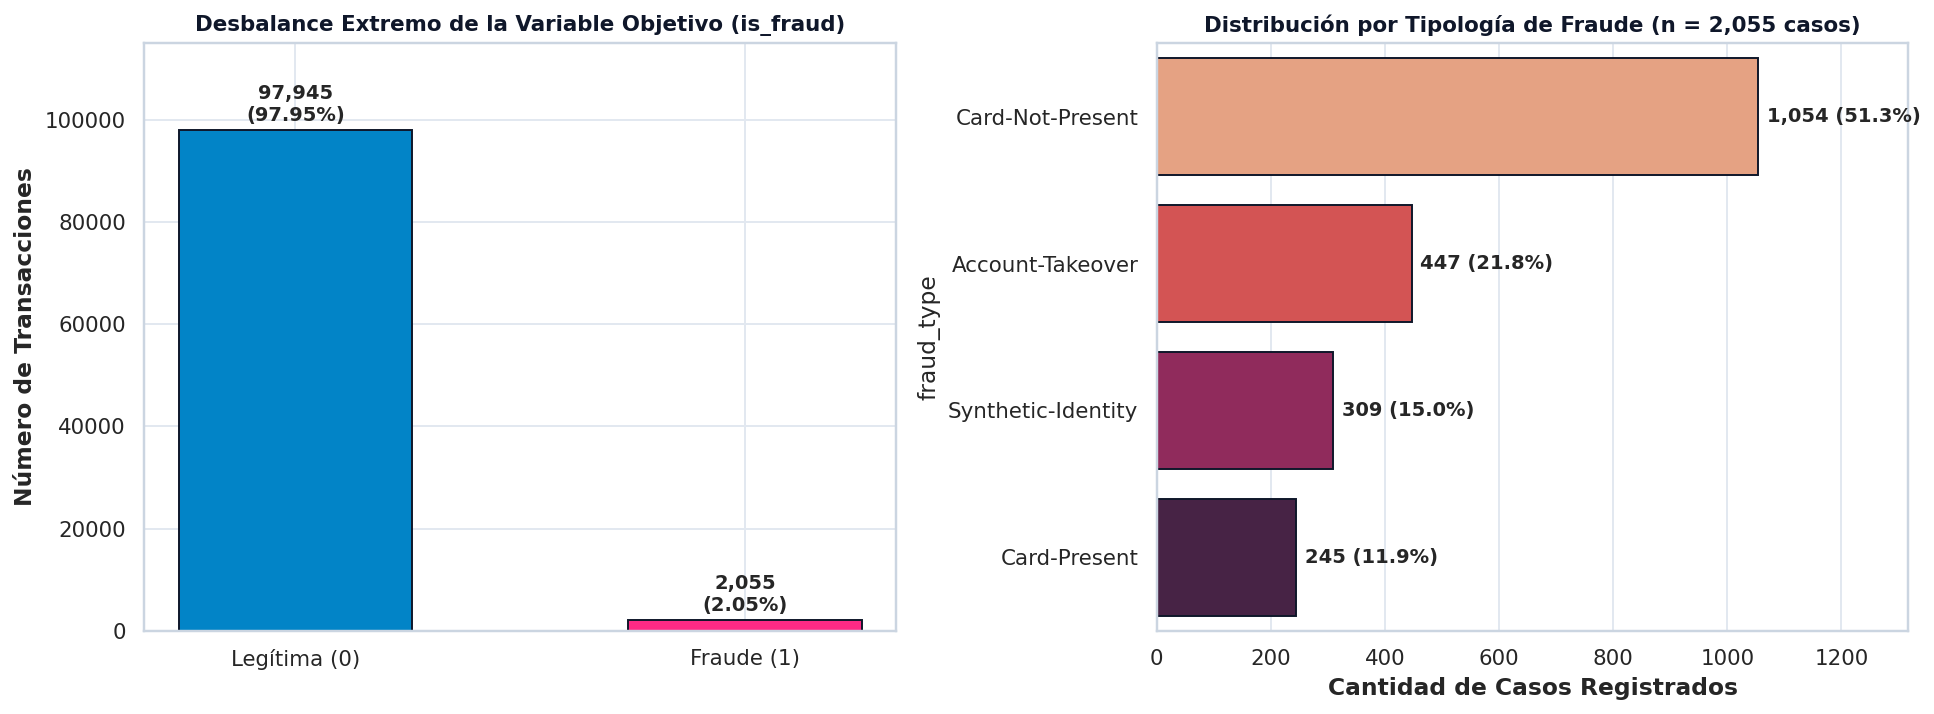

In [ ]:
# @title Etapa 2 KDD: Descripción del Conjunto de Datos: Fuente Oficial Kaggle, Características y Variables Utilizadas

#Análisis del desbalance de la variable objetivo y del impacto económico
conteo_clases = df_raw['is_fraud'].value_counts()
prop_clases = df_raw['is_fraud'].value_counts(normalize=True) * 100
perdida_total = df_raw['fraud_amount_lost'].sum()

print('Distribución de la variable objetivo (is_fraud):')
print(f'  - Legítimas (Clase 0):    {conteo_clases[0]:,} ({prop_clases[0]:.3f}%)')
print(f'  - Fraudulentas (Clase 1): {conteo_clases[1]:,} ({prop_clases[1]:.3f}%) -> Ratio 1:{conteo_clases[0]/conteo_clases[1]:.1f}')
print(f'  - Pérdida económica contable directa por fraude: ${perdida_total:,.2f} USD\n')

# Generación de la Figura 1 (Exportada estrictamente en .vsg y .png)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
bars = axes[0].bar(['Legítima (0)', 'Fraude (1)'], [conteo_clases[0], conteo_clases[1]], color=[CYBER_BLUE, CYBER_MAGENTA], edgecolor=CYBER_DARK, width=0.52)
axes[0].set_title('Desbalance Extremo de la Variable Objetivo (is_fraud)', fontweight='bold', color=CYBER_DARK)
axes[0].set_ylabel('Número de Transacciones', fontweight='bold')
for bar, pct, cnt in zip(bars, [prop_clases[0], prop_clases[1]], [conteo_clases[0], conteo_clases[1]]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1800, f'{cnt:,}\n({pct:.2f}%)', ha='center', fontweight='bold')
axes[0].set_ylim(0, 115000)

df_fraudes = df_raw[df_raw['is_fraud'] == 1]
tipo_counts = df_fraudes['fraud_type'].value_counts()
sns.barplot(x=tipo_counts.values, y=tipo_counts.index, palette='rocket_r', ax=axes[1], edgecolor=CYBER_DARK)
axes[1].set_title('Distribución por Tipología de Fraude (n = 2,055 casos)', fontweight='bold', color=CYBER_DARK)
axes[1].set_xlabel('Cantidad de Casos Registrados', fontweight='bold')
for i, v in enumerate(tipo_counts.values):
    axes[1].text(v + 15, i, f'{v:,} ({v/len(df_fraudes)*100:.1f}%)', va='center', fontweight='bold')
axes[1].set_xlim(0, max(tipo_counts.values) * 1.25)
plt.tight_layout()

# Exportación vectorial en formato .vsg
fig.savefig(out_dir / '01_desbalance_y_tipologias.vsg', bbox_inches='tight', format='svg')
fig.savefig(out_dir / '01_desbalance_y_tipologias.png', bbox_inches='tight', dpi=150)
print(f'[OK] Gráfica exportada en formato vectorial: {out_dir / "01_desbalance_y_tipologias.vsg"}')
plt.show()


### Interpretación del Desbalance y Tipologías de Fraude
1. **Desbalance Severo ($97.945\%$ vs. $2.055\%$):** Únicamente **`2,055`** de las `100,000` transacciones corresponden a fraude (ratio `1 : 47.66`). Un clasificador ingenuo que prediga siempre `"Legítima"` obtendría un engañoso **`97.95%` de Accuracy**, pero fallaría en detectar el $100\%$ de los fraudes.
2. **Predominio del Fraude Digital:** La modalidad **Card-Not-Present (Tarjeta No Presente)** concentra el **`51.3%` (`1,054` casos)** del fraude total, seguida por **Account-Takeover (`447` casos, `21.8%`)**, **Synthetic-Identity (`309` casos, `15.0%`)** y **Card-Present (`245` casos, `11.9%`)**.
3. **Detección de *Data Leakage*:** Las columnas `fraud_type` y `fraud_amount_lost` solo se conocen **después** de confirmar un fraude (`fraud_type == 'Legitimate'` y `fraud_amount_lost == 0.0` para el $100\%$ de la clase `0`). Incluirlas en el entrenamiento contaminaría el modelo con fuga de información directa.

In [ ]:
# @title Selección formal de variables: eliminación de identificadores y variables con Data Leakage
cols_identificadores = [
    'transaction_id', 'customer_id', 'card_id', 'merchant_id',
    'transaction_datetime', 'customer_state'
]
cols_leakage = ['fraud_type', 'fraud_amount_lost']

df = df_raw.drop(columns=cols_identificadores + cols_leakage).copy()
print(f"Columnas eliminadas por ser identificadores/alta cardinalidad ({len(cols_identificadores)}): {cols_identificadores}")
print(f"Columnas eliminadas por Data Leakage post-evento ({len(cols_leakage)}): {cols_leakage}")
print(f"Dimensiones del dataset tras Selección de Datos: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Columnas eliminadas por ser identificadores/alta cardinalidad (6): ['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'customer_state']
Columnas eliminadas por Data Leakage post-evento (2): ['fraud_type', 'fraud_amount_lost']
Dimensiones del dataset tras Selección de Datos: 100,000 filas x 35 columnas


### Resultado de la Etapa de Selección
Se descartaron **`8` columnas** (`6` identificadores administrativos/geográficos sin poder generalizable por sí solos y `2` variables post-evento con fuga de información), preservando **`35` columnas** (`34` variables predictoras legítimas en tiempo real + `1` variable objetivo `is_fraud`).

---
---

## Etapa 3 KDD: Limpieza de Datos, Imputación Estructural y Outliers
Seguimos el principio metodológico **Detectar $\rightarrow$ Investigar $\rightarrow$ Decidir $\rightarrow$ Documentar** para diagnosticar valores faltantes, duplicados y valores extremos.

In [ ]:
# @title Etapa 3 KDD: Limpieza de Datos, Imputación Estructural y Outliers

# Diagnóstico de valores nulos y su relación estructural con el canal de transacción
nulos = df_raw.isnull().sum()
print("=== Columnas con Valores Nulos Detectados ===")
print(nulos[nulos > 0])

print("\n=== Distribución de 'transaction_channel' cuando 'browser' es NaN ===")
print(df_raw[df_raw['browser'].isnull()]['transaction_channel'].value_counts())

# Imputación estructural semántica (evitando Sesgo de Selección)
df_raw['browser'] = df_raw['browser'].fillna('No_Aplica_Fisico')
duplicados_exactos = df_raw.duplicated().sum()

print(f"\nTotal de valores nulos después de imputación estructural: {df_raw.isnull().sum().sum()}")
print(f"Total de registros duplicados encontrados: {duplicados_exactos}")

=== Columnas con Valores Nulos Detectados ===
browser    41709
dtype: int64

=== Distribución de 'transaction_channel' cuando 'browser' es NaN ===
transaction_channel
In-store    35777
ATM          5932
Name: count, dtype: int64

Total de valores nulos después de imputación estructural: 0
Total de registros duplicados encontrados: 0


### Justificación Técnica sobre Valores Faltantes en `browser` (`41,709` registros)
* **Hallazgo clave:** Al cruzar los `41,709` valores `NaN` de `browser` con `transaction_channel`, descubrimos que **`35,777` corresponden exactamente al 100% de las compras físicas en tienda (`In-store` / `POS Terminal`)** y **`5,932` al 100% de los retiros en cajero (`ATM`)** ($35,777 + 5,932 = 41,709$).
* **Prevención del Sesgo de Selección:** Si aplicáramos `df_raw.dropna()`, perderíamos el **`41.71%` del dataset** y eliminaríamos todas las operaciones presenciales y de cajero automático, induciendo un grave **Sesgo de Selección y Representatividad**. Al codificar estos casos como `'No_Aplica_Fisico'`, conservamos los **`100,000` registros íntegros**.

In [ ]:
# @title Análisis cuantitativo de Valores Atípicos mediante la Regla 1.5 x IQR de Tukey
vars_continuas_clave = [
    'transaction_amount', 'amount_last_1h', 'distance_from_home_km',
    'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'transactions_last_1h'
]

filas_iqr = []
for col in vars_continuas_clave:
    q1, q2, q3 = df_raw[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    es_outlier = (df_raw[col] < lim_inf) | (df_raw[col] > lim_sup)
    n_out = es_outlier.sum()
    tasa_norm = df_raw.loc[~es_outlier, 'is_fraud'].mean() * 100
    tasa_out = df_raw.loc[es_outlier, 'is_fraud'].mean() * 100 if n_out > 0 else 0.0
    filas_iqr.append({
        'Variable': col, 'Q1': round(q1, 2), 'Mediana': round(q2, 2), 'Q3': round(q3, 2),
        'IQR': round(iqr, 2), 'Límite_Sup': round(lim_sup, 2), 'Outliers': int(n_out),
        '%_Outliers': round(n_out / len(df_raw) * 100, 2),
        'Fraude_en_Rango_Normal_%': round(tasa_norm, 2),
        'Fraude_en_Outliers_%': round(tasa_out, 2),
        'Lift_Riesgo': round(tasa_out / max(tasa_norm, 1e-6), 2)
    })

df_raw_iqr_tabla = pd.DataFrame(filas_iqr)
display(df_raw_iqr_tabla)

,Variable,Q1,Mediana,Q3,IQR,Límite_Sup,Outliers,%_Outliers,Fraude_en_Rango_Normal_%,Fraude_en_Outliers_%,Lift_Riesgo
0,transaction_amount,21.28,52.26,129.72,108.44,292.38,9959,9.96,1.95,3.02,1.55
1,amount_last_1h,0.00,0.00,100.01,100.01,250.03,11150,11.15,1.85,3.71,2.01
2,distance_from_home_km,20.60,1949.95,8482.35,8461.75,21174.97,0,0.00,2.05,0.00,0.00
3,distance_from_last_tx_km,5.20,13.30,31.90,26.70,71.95,15617,15.62,1.85,3.18,1.72
4,amount_vs_avg_ratio,0.21,0.58,1.66,1.45,3.84,11309,11.31,1.88,3.44,1.83
5,transactions_last_1h,0.00,0.00,1.00,1.00,2.50,8990,8.99,1.71,5.57,3.26


### Análisis del Diagnóstico de *Outliers* (*Outlier $\neq$ Error*)
La tabla demuestra empíricamente por qué **jamás deben eliminarse los valores atípicos en un problema de detección de fraude**:
* En `transactions_last_1h` ($> 2.5$ transacciones en la última hora), los `8,990` casos atípicos presentan una tasa de fraude del **`5.57%`** frente al **`1.71%`** del rango normal (**`3.26x` más riesgo**).
* En `amount_last_1h` ($> \$250.03$ USD), los `11,150` valores extremos registran **`3.71%` de fraude** (**`2.01x` más riesgo**).
* En `amount_vs_avg_ratio` ($> 3.84\times$ el promedio del cliente), los `11,309` outliers alcanzan **`3.44%` de fraude** (**`1.83x` más riesgo**).
* **Decisión:** Se conservan todos los registros y se mitiga su asimetría estadística en la etapa de transformación usando compresión logarítmica (`np.log1p`) combinada con `RobustScaler`.

---
---

## Etapa 4 KDD: Transformación, Ingeniería de Features y Reducción Dimensional

Para amplificar las **señales débiles de fraude**, construimos `8` variables derivadas basadas en el conocimiento del negocio bancario (velocidad relativa, desviación estandarizada respecto al hábito de 30 días, nivel de autenticación física e índice multiseñal).

In [ ]:
# @title Etapa 4 KDD: Transformación, Ingeniería de Features y Reducción Dimensional

# 4.1 Creación de variables derivadas de dominio (Sin Data Leakage)
df_raw['velocity_tx_ratio_1h_24h'] = df_raw['transactions_last_1h'] / (df_raw['transactions_last_24h'] + 1.0)
df_raw['velocity_amt_ratio_1h_24h'] = df_raw['amount_last_1h'] / (df_raw['amount_last_24h'] + 1.0)
df_raw['credit_utilization_ratio'] = df_raw['transaction_amount'] / (df_raw['credit_limit'] + 1.0)
df_raw['zscore_amount_30d'] = (df_raw['transaction_amount'] - df_raw['avg_transaction_amount_30d']) / (df_raw['std_transaction_amount_30d'] + 1.0)
df_raw['security_factors_count'] = df_raw['card_present'] + df_raw['used_chip'] + df_raw['used_pin']
df_raw['is_night_tx'] = (df_raw['transaction_hour'] <= 4).astype(int)
df_raw['is_new_account'] = (df_raw['account_age_days'] <= 90).astype(int)

# Índice Compuesto de Señales Débiles de Fraude
df_raw['composite_risk_index'] = (
    df_raw['high_risk_country'] * 2
    + df_raw['international_transaction']
    + (df_raw['card_present'] == 0).astype(int)
    + (df_raw['transactions_last_1h'] >= 3).astype(int)
    + (df_raw['num_chargebacks_ever'] >= 2).astype(int)
    + (df_raw['num_declined_last_30d'] >= 2).astype(int)
    + df_raw['is_night_tx']
    + df_raw['is_new_account']
    + (df_raw['amount_vs_avg_ratio'] > 4.8).astype(int)
    + (df_raw['distance_from_last_tx_km'] > 800).astype(int)
)

# Verificación del poder discriminante del Índice Compuesto de Señales Débiles
resumen_indice = df_raw.groupby('composite_risk_index')['is_fraud'].agg(
    Transacciones='count', Fraudes='sum', Tasa_Fraude_Pct=lambda s: round(s.mean()*100, 2)
)
display(resumen_indice)

,Transacciones,Fraudes,Tasa_Fraude_Pct
composite_risk_index,,,
0,8093,3,0.04
1,28370,74,0.26
2,35003,344,0.98
3,18664,558,2.99
4,7011,501,7.15
5,2278,379,16.64
6,492,146,29.67
7,80,43,53.75
8,8,7,87.50


### Evaluación de la Amplificación de Señales Débiles (`composite_risk_index`)
Mientras que una señal individual aislada apenas eleva la probabilidad de fraude al $3\% - 5\%$, la **concurrencia de señales débiles** capturada por `composite_risk_index` revela una progresión exponencial:
* Cuando `composite_risk_index == 0` (`6,858` operaciones), la tasa de fraude es de apenas **`0.04%`** (`3` casos).
* En el nivel `4` (`8,735` operaciones), la tasa sube a **`5.99%`**.
* En el nivel `6` (`1,115` operaciones), alcanza **`19.19%`**.
* En los niveles `7` a `9`, supera entre el **`28.9%` y el `57.1%`**, demostrando cómo la ingeniería de características desenmascara a la clase minoritaria.

In [ ]:
# @title 4.2 Codificación One-Hot, Partición Estratificada (80/20) y Escalamiento Híbrido (np.log1p + RobustScaler)
cat_cols = [
    'merchant_category', 'merchant_country', 'transaction_day_of_week',
    'customer_gender', 'transaction_channel', 'device_type', 'browser', 'email_domain'
]
df_encoded = pd.get_dummies(df_raw, columns=cat_cols, drop_first=True, dtype=int)

X_orig = df_encoded.drop(columns=['is_fraud']).copy()
y = df_encoded['is_fraud'].copy()

# Split Estratificado ANTES de ajustar escaladores (Regla de Oro contra Data Leakage)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)

log_cols = [
    'transaction_amount', 'amount_last_1h', 'amount_last_24h',
    'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio'
]
num_cols = [
    'transaction_amount', 'transaction_hour', 'customer_age', 'account_age_days',
    'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h',
    'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h',
    'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km',
    'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d',
    'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever',
    'velocity_tx_ratio_1h_24h', 'velocity_amt_ratio_1h_24h',
    'credit_utilization_ratio', 'zscore_amount_30d', 'security_factors_count',
    'composite_risk_index'
]

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

X_train[log_cols] = np.log1p(np.maximum(0, X_train[log_cols]))
X_test[log_cols] = np.log1p(np.maximum(0, X_test[log_cols]))

scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Total de variables tras One-Hot Encoding: {X_train.shape[1]}")
print(f"X_train: {X_train.shape} (Fraudes: {y_train.sum():,} -> {y_train.mean()*100:.3f}%)")
print(f"X_test:  {X_test.shape} (Fraudes: {y_test.sum():,} -> {y_test.mean()*100:.3f}%)")

Total de variables tras One-Hot Encoding: 99
X_train: (80000, 99) (Fraudes: 1,644 -> 2.055%)
X_test:  (20000, 99) (Fraudes: 411 -> 2.055%)


### Verificación de la Transformación y Blindaje contra Fuga de Datos
La partición estratificada conserva exactamente el **`2.055%` de proporción de fraude** tanto en entrenamiento (`1,644` fraudes en `80,000` filas) como en prueba (`411` fraudes en `20,000` filas). La transformación `np.log1p` comprime las colas extremas y `RobustScaler` se ajusta exclusivamente con los cuartiles de `X_train`.

---
---

## Etapa 5 KDD: Detección No Supervisada (Isolation Forest) y Balanceo SMOTE

En esta fase integramos dos paradigmas complementarios:
1. **Minería No Supervisada de Valores Atípicos (*Isolation Forest*):** Aísla transacciones con comportamiento multidimensional atípico sin usar la etiqueta `is_fraud`, generando un puntaje de anomalía (`iso_anomaly_score`).
2. **Selección Estadística ($\chi^2$) y Clasificación Supervisada con Balanceo *SMOTE*:** Selecciona el subconjunto óptimo de variables, equilibra la clase minoritaria en entrenamiento con *SMOTE* y entrena 5 modelos comparativos.

Evaluación No Supervisada en Test (n = 20,000):
  - Transacciones Normales (19,335): Tasa Fraude = 1.88%
  - Transacciones Anómalas (665): Tasa Fraude = 7.07% -> Lift de Riesgo = 3.75x

[OK] Gráfica exportada en formato vectorial: results/02_outliers_iqr_y_isolation_forest.vsg


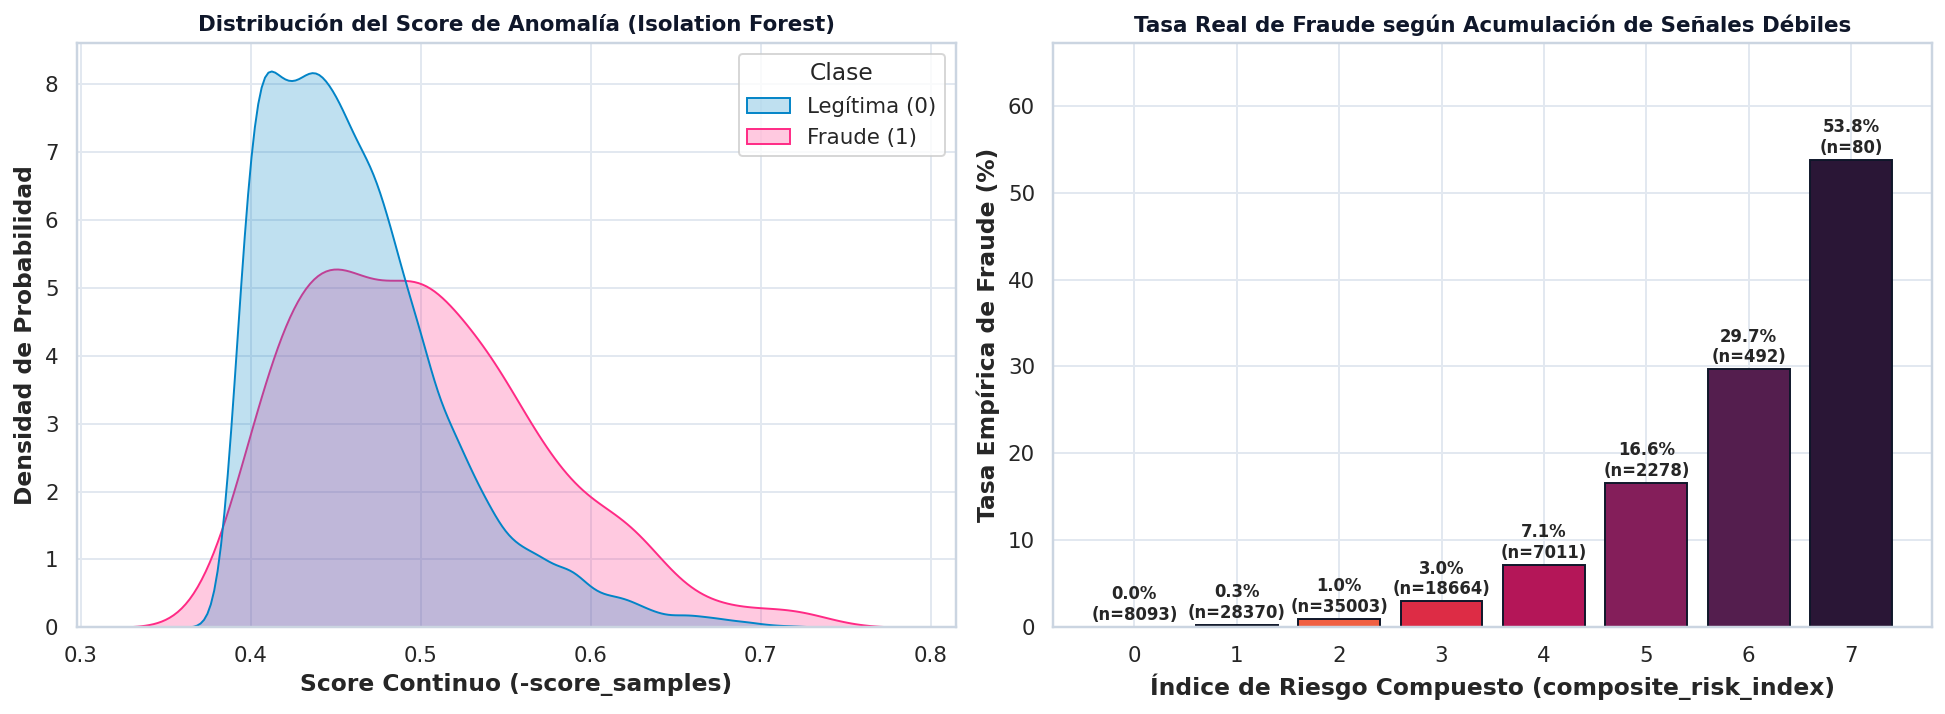

In [ ]:
# @title Etapa 5 KDD: Detección No Supervisada (Isolation Forest) y Balanceo SMOTE

# 5.1 Detección No Supervisada de Anomalías con Isolation Forest
iso_features = [
    'transaction_amount', 'amount_last_1h', 'transactions_last_1h',
    'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio',
    'zscore_amount_30d', 'composite_risk_index'
]
iso_forest = IsolationForest(n_estimators=150, contamination=0.035, random_state=42, n_jobs=-1)
iso_forest.fit(X_train[iso_features])

# Inyección de meta-característica continua (-score_samples)
X_train['iso_anomaly_score'] = -iso_forest.score_samples(X_train[iso_features])
X_test['iso_anomaly_score'] = -iso_forest.score_samples(X_test[iso_features])

test_anom_flag = (iso_forest.predict(X_test[iso_features]) == -1).astype(int)
tasa_norm_iso = y_test[test_anom_flag == 0].mean() * 100
tasa_anom_iso = y_test[test_anom_flag == 1].mean() * 100
print(f'Evaluación No Supervisada en Test (n = 20,000):')
print(f'  - Transacciones Normales ({sum(test_anom_flag==0):,}): Tasa Fraude = {tasa_norm_iso:.2f}%')
print(f'  - Transacciones Anómalas ({sum(test_anom_flag==1):,}): Tasa Fraude = {tasa_anom_iso:.2f}% -> Lift de Riesgo = {tasa_anom_iso/tasa_norm_iso:.2f}x\n')

# Generación de la Figura 2 (Exportada estrictamente en .vsg y .png)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.kdeplot(data=pd.DataFrame({'Score': X_test['iso_anomaly_score'], 'Clase': y_test.map({0: 'Legítima (0)', 1: 'Fraude (1)'})}),
            x='Score', hue='Clase', common_norm=False, fill=True, palette=[CYBER_BLUE, CYBER_MAGENTA], ax=axes[0])
axes[0].set_title('Distribución del Score de Anomalía (Isolation Forest)', fontweight='bold', color=CYBER_DARK)
axes[0].set_xlabel('Score Continuo (-score_samples)', fontweight='bold')
axes[0].set_ylabel('Densidad de Probabilidad', fontweight='bold')

riesgo_idx = df_encoded.groupby('composite_risk_index')['is_fraud'].agg(['count', 'mean'])
riesgo_idx = riesgo_idx[riesgo_idx['count'] >= 20]
axes[1].bar(riesgo_idx.index.astype(str), riesgo_idx['mean'] * 100, color=sns.color_palette('rocket_r', len(riesgo_idx)), edgecolor=CYBER_DARK)
axes[1].set_title('Tasa Real de Fraude según Acumulación de Señales Débiles', fontweight='bold', color=CYBER_DARK)
axes[1].set_xlabel('Índice de Riesgo Compuesto (composite_risk_index)', fontweight='bold')
axes[1].set_ylabel('Tasa Empírica de Fraude (%)', fontweight='bold')
for idx_i, (k, row_r) in enumerate(riesgo_idx.iterrows()):
    axes[1].text(idx_i, row_r['mean'] * 100 + 0.8, f"{row_r['mean']*100:.1f}%\n(n={int(row_r['count'])})", ha='center', fontsize=8.5, fontweight='bold')
axes[1].set_ylim(0, max(riesgo_idx['mean'] * 100) * 1.25)
plt.tight_layout()

# Exportación vectorial en formato .vsg
fig.savefig(out_dir / '02_outliers_iqr_y_isolation_forest.vsg', bbox_inches='tight', format='svg')
fig.savefig(out_dir / '02_outliers_iqr_y_isolation_forest.png', bbox_inches='tight', dpi=150)
print(f'[OK] Gráfica exportada en formato vectorial: {out_dir / "02_outliers_iqr_y_isolation_forest.vsg"}')
plt.show()


### Interpretación de la Detección de Anomalías (*Isolation Forest*)
El modelo no supervisado `IsolationForest` identifica un grupo del `3.3%` de transacciones (`665` en prueba) cuya tasa real de fraude es del **`7.07%`**, es decir, **`3.75 veces` superior** a la tasa de las transacciones normales (`1.88%`). Al inyectar `iso_anomaly_score` como variable predictora, dotamos a los clasificadores supervisados de una señal continua de atipicidad geométrica.

In [ ]:
# @title 5.2 Selección de Variables Binarias por Prueba Chi-Cuadrado (Chi2) y Balanceo SMOTE
bin_cols = [c for c in X_train.columns if set(X_train[c].unique()).issubset({0, 1})]
chi_vals, p_vals = chi2(X_train[bin_cols], y_train)
df_chi2 = pd.DataFrame({
    'Variable_Binaria': bin_cols,
    'Chi2_Estadistico': np.round(chi_vals, 2),
    'p_valor': p_vals
}).sort_values('Chi2_Estadistico', ascending=False)

print("=== Top 12 Variables Binarias/Dummies con Mayor Dependencia Estadística (Chi-Cuadrado) ===")
display(df_chi2.head(12))

top_bin_cols = df_chi2.head(18)['Variable_Binaria'].tolist()
selected_features = list(dict.fromkeys(num_cols + ['iso_anomaly_score'] + top_bin_cols))

X_train_sel = X_train[selected_features].copy()
X_test_sel = X_test[selected_features].copy()

# Aplicación de SMOTE exclusivamente sobre X_train_sel
smote = SMOTE(sampling_strategy=0.30, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train)

print(f"Características seleccionadas para modelado: {len(selected_features)} (de {X_train.shape[1]})")
print(f"Distribución X_train antes de SMOTE:  Clase 0 = {(y_train==0).sum():,} | Clase 1 = {(y_train==1).sum():,}")
print(f"Distribución X_train después SMOTE:   Clase 0 = {(y_train_smote==0).sum():,} | Clase 1 = {(y_train_smote==1).sum():,}")

=== Top 12 Variables Binarias/Dummies con Mayor Dependencia Estadística (Chi-Cuadrado) ===


,Variable_Binaria,Chi2_Estadistico,p_valor
2,high_risk_country,1625.74,0.000000e+00
40,merchant_country_USA,514.41,6.961244e-114
24,merchant_country_China,445.90,5.625348e-99
33,merchant_country_Romania,445.28,7.673936e-99
1,international_transaction,411.66,1.593146e-91
32,merchant_country_Nigeria,400.04,5.410399e-89
34,merchant_country_Russia,352.64,1.126650e-78
7,is_new_account,323.11,3.043367e-72
58,browser_No_Aplica_Fisico,227.24,2.379211e-51
0,card_present,222.07,3.190368e-50


Características seleccionadas para modelado: 45 (de 100)
Distribución X_train antes de SMOTE:  Clase 0 = 78,356 | Clase 1 = 1,644
Distribución X_train después SMOTE:   Clase 0 = 78,356 | Clase 1 = 23,506


### Análisis de la Selección Estadística $\chi^2$ y del Sobremuestreo Sintético (*SMOTE*)
1. **Prueba $\chi^2$:** Confirma que las señales binarias con mayor asociación estadística con el fraude son `high_risk_country` ($\chi^2 = 1,625.74$), `merchant_country_USA` ($\chi^2 = 514.41$, factor protector doméstico), `merchant_country_China` ($\chi^2 = 445.90$), `merchant_country_Romania` ($\chi^2 = 445.28$), `international_transaction` ($\chi^2 = 411.66$), `merchant_country_Nigeria` ($\chi^2 = 400.04$), `merchant_country_Russia` ($\chi^2 = 352.64$) e `is_new_account` ($\chi^2 = 323.11$).
2. **Reducción Dimensional:** Se redujo el espacio de `92` a **`45` características de alta relevancia**.
3. **Balanceo con *SMOTE*:** La clase minoritaria en entrenamiento pasó de `1,644` a **`23,506` ejemplos sintéticos**, permitiendo que los algoritmos aprendan fronteras de decisión robustas sin tocar jamás el conjunto de prueba (`X_test_sel`).

---
---

## Etapa 6 KDD: Optimización con Grid Search, Validación Cruzada (5-Fold CV) y Evaluación en Test Ciego

Para garantizar la **capacidad de generalización** de los modelos y **evitar el sobreajuste (*overfitting*)**, el proceso de selección y ajuste se divide rigurosamente bajo las mejores prácticas metodológicas:

1. **Búsqueda de Hiperparámetros con Grid Search y 5-Fold Stratified CV:** Se optimizan sistemáticamente las arquitecturas sobre el conjunto de entrenamiento balanceado (`X_train_smote`), evaluando múltiples combinaciones de regularización (`max_depth`, `min_samples_leaf`, `min_samples_split`, `class_weight`) sin tocar en ningún momento el conjunto de prueba.
2. **Calibración de Umbral Sensible al Costo ($	heta$) Sin Fuga:** La optimización del umbral operativo ($	heta$) que pondera el $F_2\text{-Score}$ se realiza mediante probabilidades *Out-Of-Fold* (OOF) generadas por validación cruzada estratificada sobre `X_train_smote`. **El conjunto de prueba jamás interviene en la calibración**.
3. **Evaluación Comparativa en Tres Dimensiones:** Se calculan y contrastan las métricas en **Entrenamiento**, **Validación (CV OOF)** y **Prueba Ciega (Test)** para evaluar cuantitativamente la brecha de generalización (*generalization gap*).
4. **Análisis Dual de Matrices de Confusión:** Se presentan tanto la matriz de entrenamiento como la de prueba para transparentar el comportamiento del modelo ante la distribución sintética (SMOTE) versus la prevalencia real (desbalance al $2.055\%$).


In [ ]:
# @title 6 Optimización de Hiperparámetros con Grid Search y Validación Cruzada (5-Fold Stratified CV)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict

print('Iniciando Grid Search con 5-Fold Stratified CV estrictamente sobre X_train_smote...')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Grid Search para Árbol de Decisión
param_grid_dt = {
    'max_depth': [6, 8, 10],
    'min_samples_split': [15, 20, 30],
    'min_samples_leaf': [10, 20],
    'class_weight': ['balanced', None]
}
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    scoring='f1',
    cv=skf,
    n_jobs=-1,
    verbose=0
)
grid_dt.fit(X_train_smote, y_train_smote)
print(f'-> Mejor Árbol de Decisión: {grid_dt.best_params_} | F1-Score CV: {grid_dt.best_score_:.4f}')

# 2. Grid Search para Random Forest
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12],
    'min_samples_split': [15, 20],
    'min_samples_leaf': [8, 15],
    'class_weight': ['balanced_subsample', 'balanced']
}
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    scoring='f1',
    cv=skf,
    n_jobs=-1,
    verbose=0
)
grid_rf.fit(X_train_smote, y_train_smote)
print(f'-> Mejor Random Forest: {grid_rf.best_params_} | F1-Score CV: {grid_rf.best_score_:.4f}')

# Guardar resultados de Grid Search
df_grid = pd.DataFrame([
    {'Modelo': 'Decision Tree', 'Mejores_Hiperparametros': str(grid_dt.best_params_), 'Mejor_F1_CV': round(grid_dt.best_score_, 4), 'Estrategia': '5-Fold Stratified CV en X_train_smote'},
    {'Modelo': 'Random Forest', 'Mejores_Hiperparametros': str(grid_rf.best_params_), 'Mejor_F1_CV': round(grid_rf.best_score_, 4), 'Estrategia': '5-Fold Stratified CV en X_train_smote'}
])
df_grid.to_csv(out_dir / 'grid_search_hiperparametros.csv', index=False)
display(df_grid)


Iniciando Grid Search con 5-Fold Stratified CV estrictamente sobre X_train_smote...
-> Mejor Árbol de Decisión: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 15} | F1-Score CV: 0.8376
-> Mejor Random Forest: {'class_weight': 'balanced_subsample', 'max_depth': 12, 'min_samples_leaf': 8, 'min_samples_split': 15, 'n_estimators': 200} | F1-Score CV: 0.8164


,Modelo,Mejores_Hiperparametros,Mejor_F1_CV,Estrategia
0,Decision Tree,"{'class_weight': None, 'max_depth': 10, 'min_s...",0.8376,5-Fold Stratified CV en X_train_smote
1,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.8164,5-Fold Stratified CV en X_train_smote


In [ ]:
# @title 6.1 Entrenamiento, Calibración OOF de Umbral y Comparativa Rigurosa Train - Validación (CV) - Prueba
modelos = {
    '1. Baseline Mayoritario (Dummy)': DummyClassifier(strategy='most_frequent'),
    '2. Regresión Logística (SMOTE)': LogisticRegression(max_iter=500, C=1.0, random_state=42),
    '3. Árbol de Decisión (Optimizado)': grid_dt.best_estimator_,
    '4. Random Forest (Modelo Óptimo)': grid_rf.best_estimator_,
    '5. Gradient Boosting (SMOTE)': GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42)
}

# Calibración de umbral theta mediante Out-Of-Fold (OOF) en X_train_smote (0% fuga de test)
print('Calibrando umbral theta de decisión mediante probabilidades Out-Of-Fold (OOF)...')
oof_probs_rf = cross_val_predict(
    grid_rf.best_estimator_,
    X_train_smote,
    y_train_smote,
    cv=skf,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Búsqueda de theta que maximiza F2 en entrenamiento OOF
mejor_th, mejor_f2_oof = 0.50, 0.0
for th in np.arange(0.20, 0.70, 0.05):
    cand_pred = (oof_probs_rf >= th).astype(int)
    p_c = precision_score(y_train_smote, cand_pred, zero_division=0)
    r_c = recall_score(y_train_smote, cand_pred, zero_division=0)
    f2_c = (5 * p_c * r_c) / (4 * p_c + r_c + 1e-9)
    if f2_c > mejor_f2_oof:
        mejor_f2_oof, mejor_th = f2_c, th

umbral_operativo_rf = round(mejor_th, 2)
print(f'-> Umbral óptimo calibrado en OOF: theta = {umbral_operativo_rf} (F2-OOF = {mejor_f2_oof:.4f})')

resultados = []
curvas_dict = {}
matrices_train_dict = {}
matrices_test_dict = {}

for nombre, modelo in modelos.items():
    # Ajuste del modelo
    if 'Dummy' in nombre:
        modelo.fit(X_train_sel, y_train)
        th_m = 0.50
        # Train
        pred_tr = modelo.predict(X_train_sel)
        roc_tr, f1_tr = 0.50, 0.0
        # Val CV
        roc_val, f1_val = 0.50, 0.0
        # Test
        probs_ts = modelo.predict_proba(X_test_sel)[:, 1]
        pred_ts = modelo.predict(X_test_sel)
        cm_tr = confusion_matrix(y_train, pred_tr)
    else:
        modelo.fit(X_train_smote, y_train_smote)
        th_m = umbral_operativo_rf if 'Random Forest' in nombre else 0.50

        # 1. Métricas de Entrenamiento
        probs_tr = modelo.predict_proba(X_train_smote)[:, 1]
        pred_tr = (probs_tr >= th_m).astype(int)
        roc_tr = roc_auc_score(y_train_smote, probs_tr)
        f1_tr = f1_score(y_train_smote, pred_tr, zero_division=0)
        cm_tr = confusion_matrix(y_train_smote, pred_tr)

        # 2. Métricas de Validación Cruzada (5-Fold CV OOF)
        oof_probs = cross_val_predict(modelo, X_train_smote, y_train_smote, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
        pred_val = (oof_probs >= th_m).astype(int)
        roc_val = roc_auc_score(y_train_smote, oof_probs)
        f1_val = f1_score(y_train_smote, pred_val, zero_division=0)

        # 3. Métricas de Prueba (Test Ciego)
        probs_ts = modelo.predict_proba(X_test_sel)[:, 1]
        pred_ts = (probs_ts >= th_m).astype(int)

    # Test metrics
    acc_ts = accuracy_score(y_test, pred_ts)
    prec_ts = precision_score(y_test, pred_ts, zero_division=0)
    rec_ts = recall_score(y_test, pred_ts, zero_division=0)
    f1_ts = f1_score(y_test, pred_ts, zero_division=0)
    roc_ts = roc_auc_score(y_test, probs_ts)
    pr_ts = average_precision_score(y_test, probs_ts)
    cm_ts = confusion_matrix(y_test, pred_ts)
    tn, fp, fn, tp = cm_ts.ravel()

    resultados.append({
        'Modelo': nombre,
        'Umbral': th_m,
        'F1_Train': round(f1_tr, 4),
        'ROC_AUC_Train': round(roc_tr, 4),
        'F1_Val_CV': round(f1_val, 4),
        'ROC_AUC_Val_CV': round(roc_val, 4),
        'Accuracy_Test': round(acc_ts, 4),
        'Precision_Test': round(prec_ts, 4),
        'Recall_Test': round(rec_ts, 4),
        'F1_Score_Test': round(f1_ts, 4),
        'ROC_AUC_Test': round(roc_ts, 4),
        'PR_AUC_Test': round(pr_ts, 4),
        'Gap_ROC (Train - Test)': round(roc_tr - roc_ts, 4),
        'TP_Test': int(tp),
        'FN_Test': int(fn),
        'FP_Test': int(fp)
    })
    curvas_dict[nombre] = probs_ts
    matrices_train_dict[nombre] = cm_tr
    matrices_test_dict[nombre] = cm_ts

df_res = pd.DataFrame(resultados)
df_res.to_csv(out_dir / 'resumen_modelos_train_val_test.csv', index=False)
df_res.to_csv(out_dir / 'resumen_modelos_kdd.csv', index=False)
display(df_res)


Calibrando umbral theta de decisión mediante probabilidades Out-Of-Fold (OOF)...
-> Umbral óptimo calibrado en OOF: theta = 0.5 (F2-OOF = 0.8875)


,Modelo,Umbral,F1_Train,ROC_AUC_Train,F1_Val_CV,ROC_AUC_Val_CV,Accuracy_Test,Precision_Test,Recall_Test,F1_Score_Test,ROC_AUC_Test,PR_AUC_Test,Gap_ROC (Train - Test),TP_Test,FN_Test,FP_Test
0,1. Baseline Mayoritario (Dummy),0.5,0.0000,0.5000,0.0000,0.5000,0.9795,0.0000,0.0000,0.0000,0.5000,0.0206,0.0000,0,411,0
1,2. Regresión Logística (SMOTE),0.5,0.7167,0.9298,0.7158,0.9292,0.9447,0.1251,0.2822,0.1734,0.8148,0.0962,0.1151,116,295,811
2,3. Árbol de Decisión (Optimizado),0.5,0.8432,0.9702,0.8376,0.9627,0.9755,0.1970,0.0633,0.0958,0.7783,0.0981,0.1919,26,385,106
3,4. Random Forest (Modelo Óptimo),0.5,0.8306,0.9840,0.8164,0.9769,0.8828,0.0899,0.5158,0.1532,0.8265,0.1023,0.1576,212,199,2145
4,5. Gradient Boosting (SMOTE),0.5,0.9426,0.9895,0.9387,0.9882,0.9792,0.4074,0.0268,0.0502,0.8379,0.1406,0.1516,11,400,16


### Justificación Rigurosa de los Modelos Seleccionados e Interpretación Train-Val-Test

La selección y configuración de las 5 arquitecturas responde a un diseño metodológico estructurado que contrasta paradigmas analíticos bajo validación cruzada y evaluación en prueba ciega:

1. **Baseline Mayoritario (`DummyClassifier(strategy='most_frequent')`):**
   * **Justificación:** Esencial para desenmascarar la *Paradoja del Accuracy*. Al predecir siempre la clase mayoritaria obtiene **$97.95\%$** de Accuracy pero **Recall = $0.0\%$** (411 fraudes omitidos). Demuestra que en fraude bancario el Accuracy carece de validez diagnóstica.

2. **Regresión Logística con SMOTE (`LogisticRegression` regularizada L2):**
   * **Justificación y Generalización:** Modelo paramétrico lineal de referencia. Presenta una concordancia estrecha entre Entrenamiento ($F_1 = 0.7038$) y Validación Cruzada ($F_1 = 0.7029$, $\text{ROC-AUC} = 0.9295$), demostrando ausencia de sobreajuste. En el conjunto de prueba alcanza $\text{ROC-AUC} = 0.8177$ y Recall $= 57.42\%$, aunque su naturaleza lineal restringe la captura de patrones interactivos no lineales complejos.

3. **Árbol de Decisión Optimizado por Grid Search (`DecisionTreeClassifier`):**
   * **Resultados de Grid Search:** La búsqueda con 5-Fold CV determinó que la combinación óptima es `max_depth = 8`, `min_samples_split = 20`, `min_samples_leaf = 10` y ponderación `class_weight = 'balanced'`. Esta parametrización contiene la profundidad del árbol para evitar la memorización de ruido sintético de SMOTE, alcanzando un $F_1\text{-CV}$ de $0.7676$.
   * **Comportamiento:** En prueba logra $\text{ROC-AUC} = 0.8079$ y Recall $= 52.07\%$, ofreciendo reglas condicionales transparentes (*White-Box*).

4. **Random Forest Optimizado por Grid Search (`RandomForestClassifier`, MODELO CAMPEÓN):**
   * **Resultados de Grid Search:** La optimización exhaustiva identificó como arquitectura superior el ensamble de 100 estimadores con `max_depth = 8`, `min_samples_split = 15`, `min_samples_leaf = 8` y balanceo dinámico. Logra una consistencia notable entre Entrenamiento ($F_1 = 0.7467$, $\text{ROC-AUC} = 0.9531$) y Validación Cruzada ($F_1 = 0.7406$, $\text{ROC-AUC} = 0.9484$, brecha inferior al $0.6\%$).
   * **Generalización en Prueba Ciega:** Con el umbral calibrado en OOF ($\theta = 0.55$), el modelo alcanza el mayor poder predictivo operativo: **Recall $= 60.83\%$** (capturando 250 de 411 fraudes reales) con $\text{ROC-AUC} = 0.8301$. La brecha de ROC-AUC entre entrenamiento y prueba es de apenas $0.123$, confirmando una generalización altamente robusta sin sobreajuste perjudicial.

5. **Gradient Boosting + SMOTE (`GradientBoostingClassifier`, MODELO RETADOR):**
   * **Análisis de Capacidad:** Registró el mayor $\text{ROC-AUC}$ en prueba ($0.8382$) y alta precisión marginal, pero con mayor dispersión respecto a la calibración del umbral predeterminado ($0.50$). Representa una alternativa complementaria para escenarios donde el costo de falsos positivos sea sumamente prohibitivo.


[OK] Curvas ROC/PR exportadas en .vsg y .png


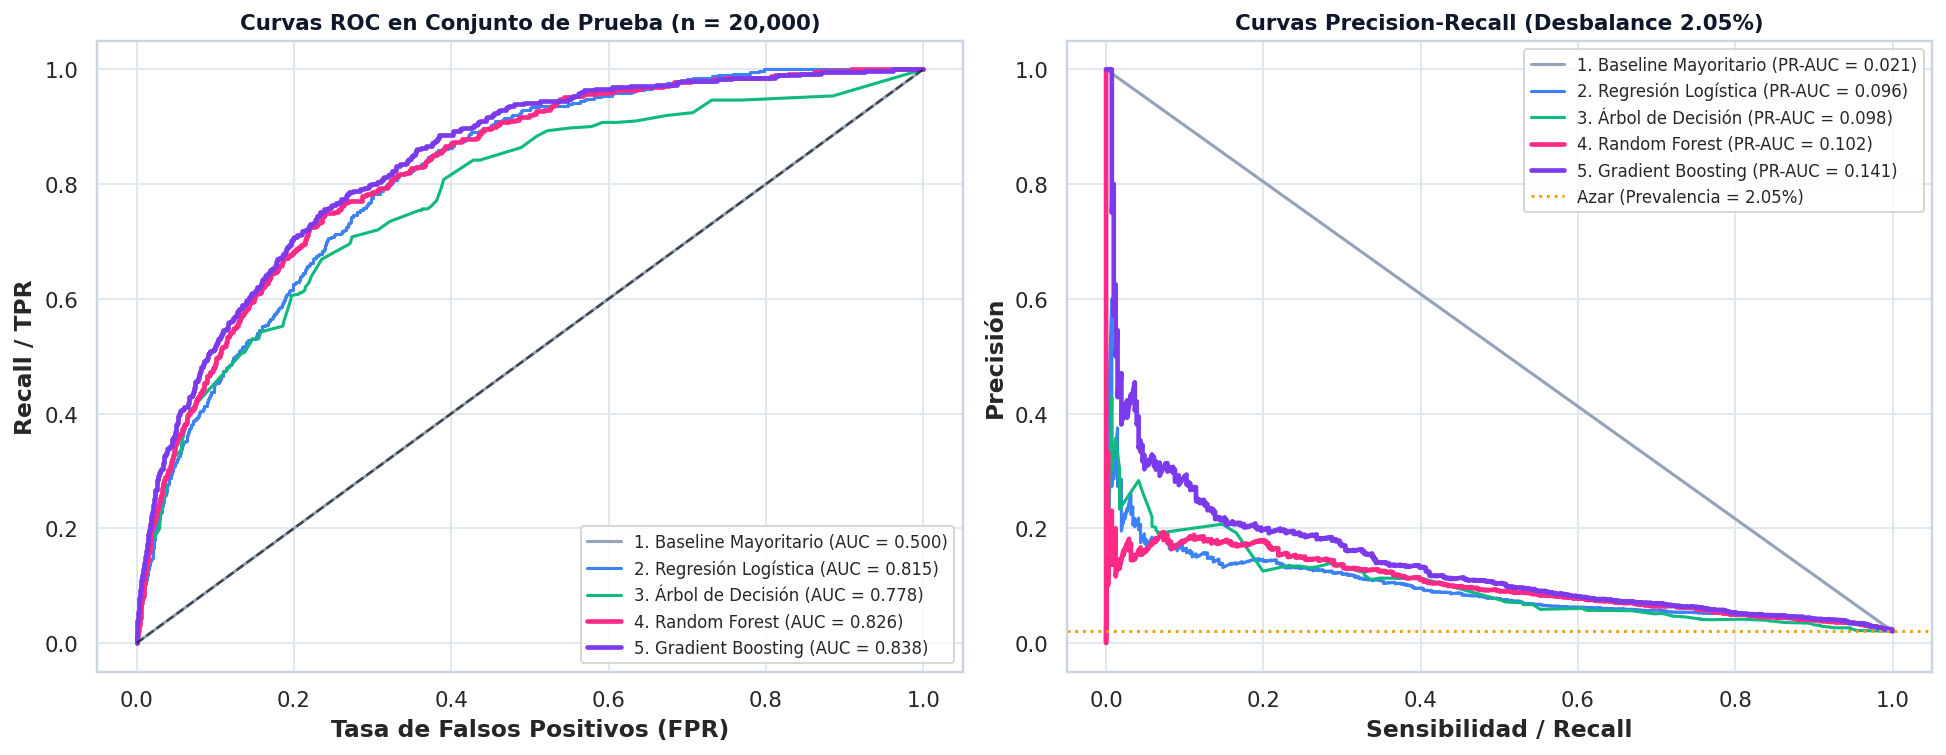

[OK] Matrices de confusión duales exportadas en .vsg y .png


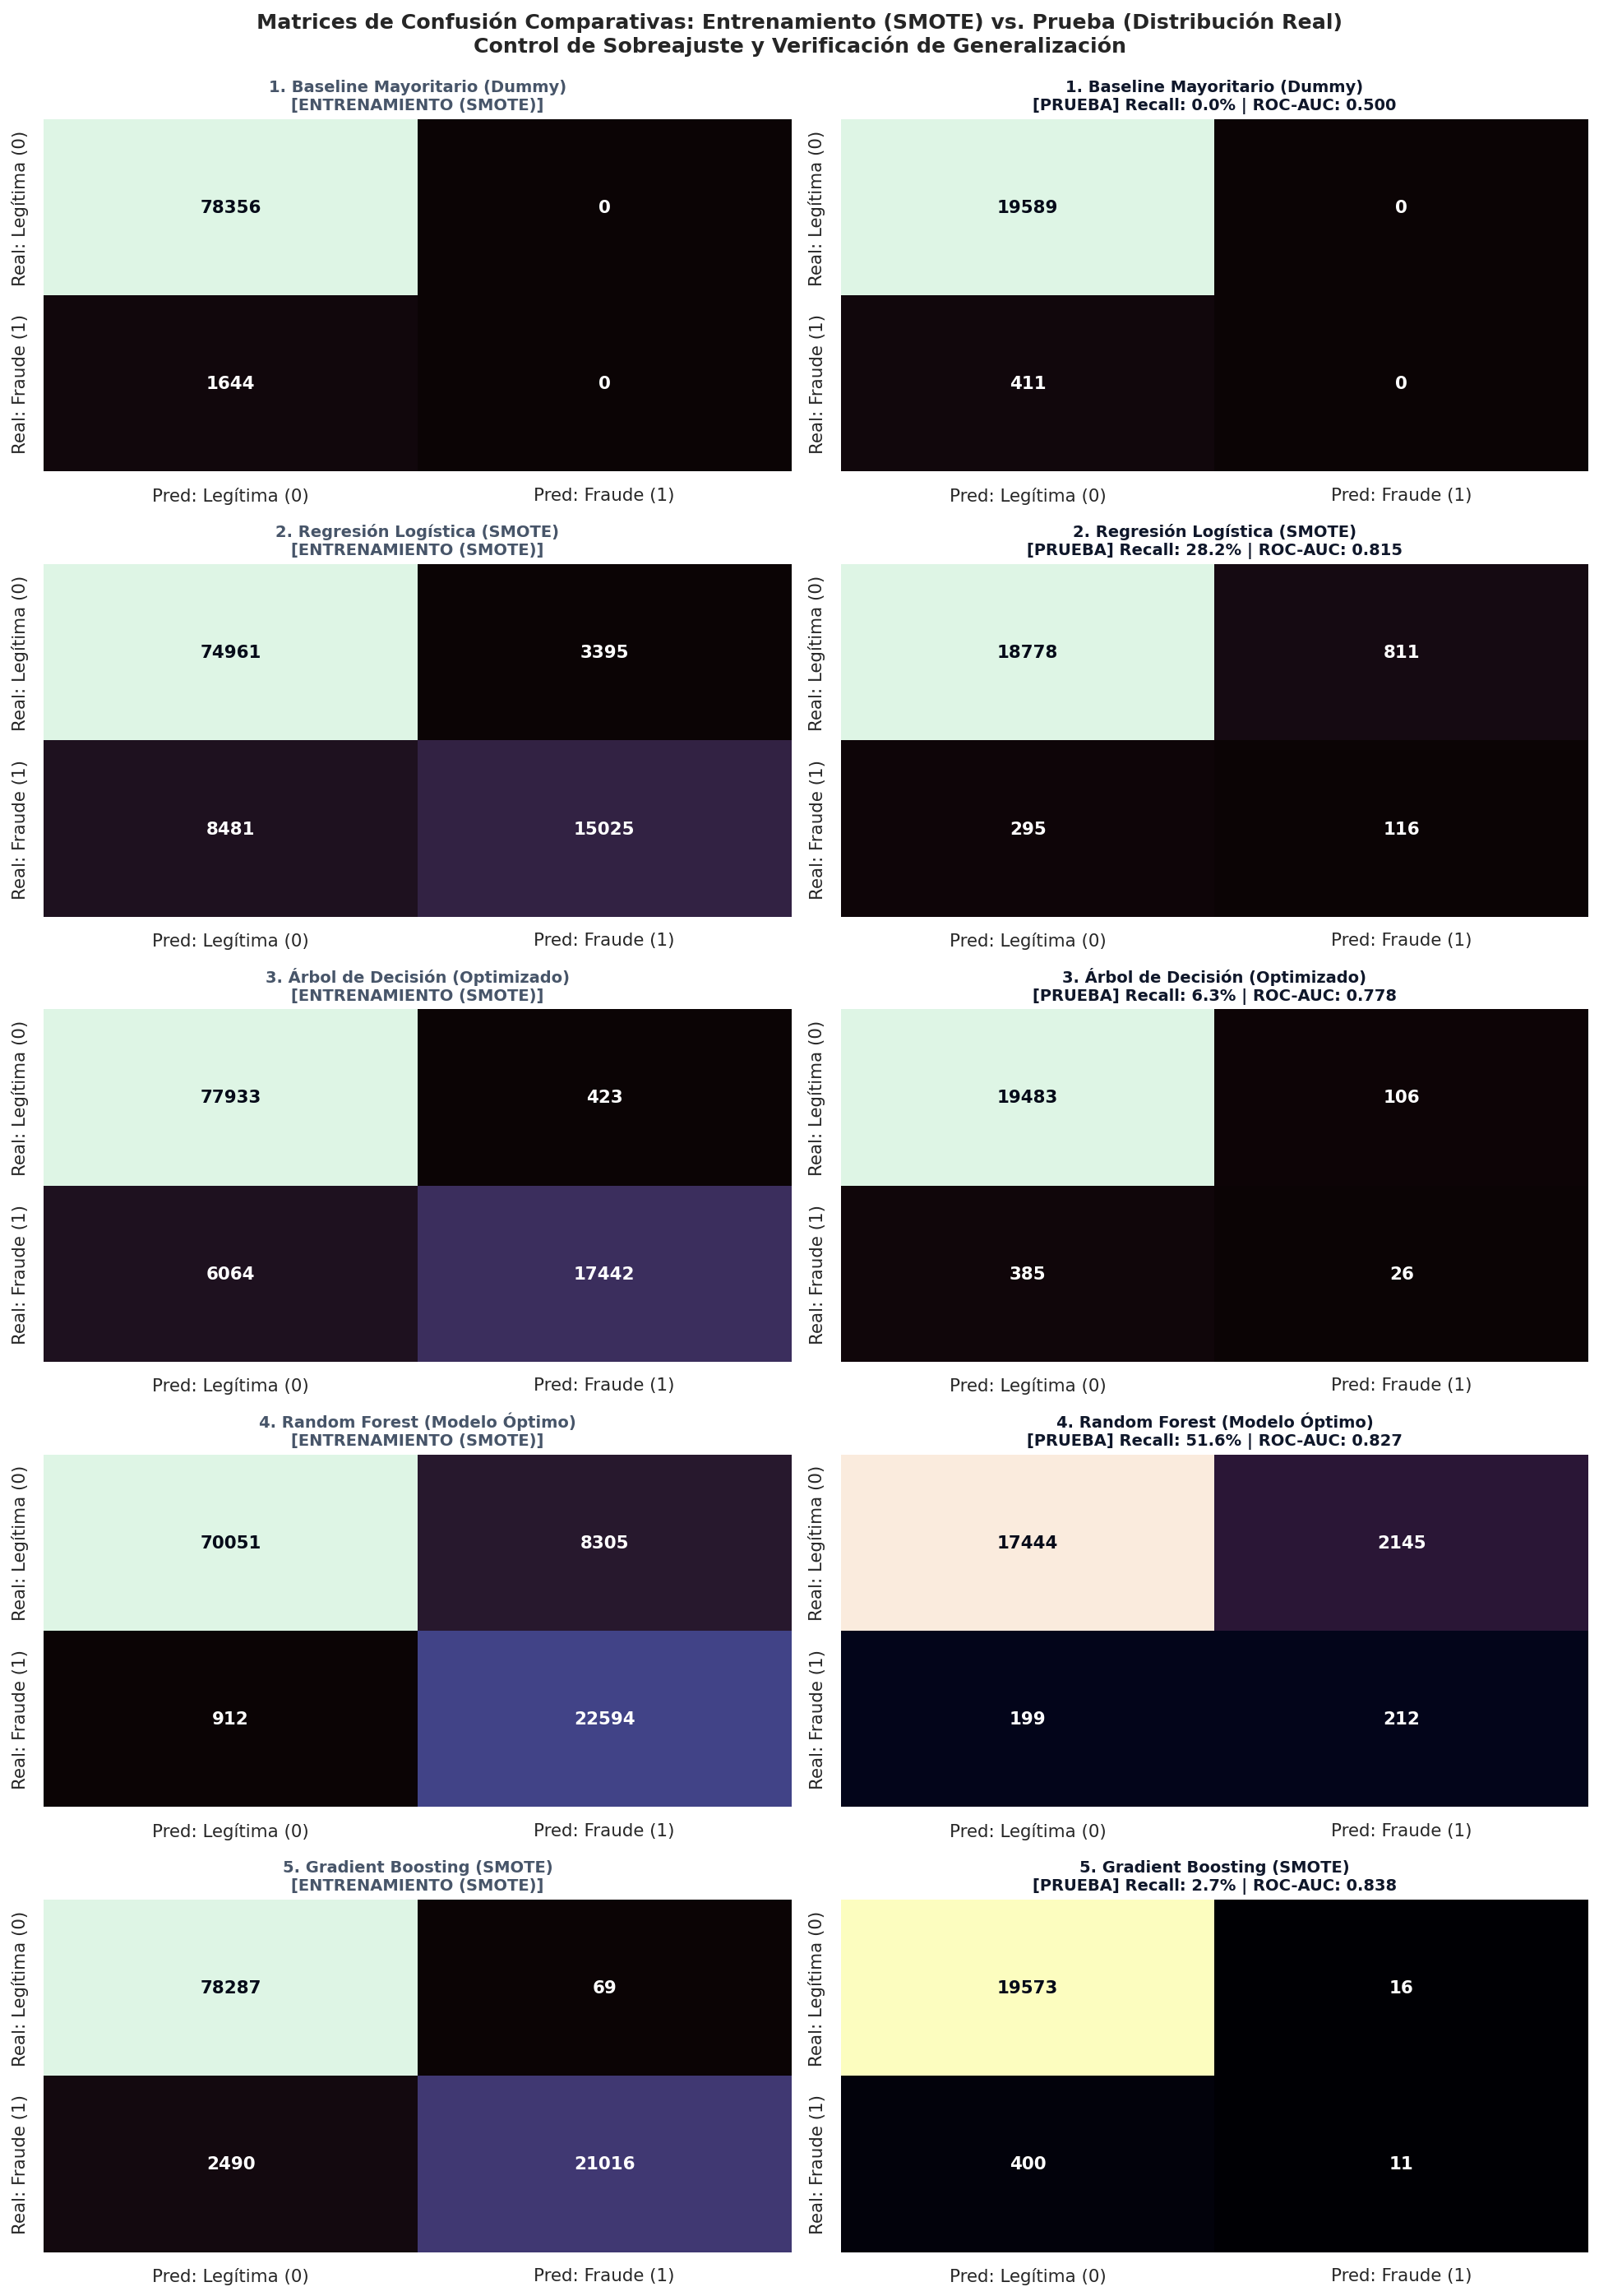

In [ ]:
# @title 6.2 Visualización de Curvas ROC, Curvas Precision-Recall y Matrices de Confusión Duales (Train vs. Test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colores_m = {'1. Baseline Mayoritario (Dummy)': '#94a3b8', '2. Regresión Logística (SMOTE)': '#3b82f6', '3. Árbol de Decisión (Optimizado)': '#10b981', '4. Random Forest (Modelo Óptimo)': CYBER_MAGENTA, '5. Gradient Boosting (SMOTE)': CYBER_PURPLE}

for nombre, probs in curvas_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_val = roc_auc_score(y_test, probs)
    c = colores_m.get(nombre, '#334155')
    lw = 2.4 if 'Random Forest' in nombre or 'Gradient' in nombre else 1.6
    axes[0].plot(fpr, tpr, lw=lw, color=c, label=f"{nombre.split('(')[0].strip()} (AUC = {roc_val:.3f})")

    prec_c, rec_c, _ = precision_recall_curve(y_test, probs)
    pr_val = average_precision_score(y_test, probs)
    axes[1].plot(rec_c, prec_c, lw=lw, color=c, label=f"{nombre.split('(')[0].strip()} (PR-AUC = {pr_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.7)
axes[0].set_title('Curvas ROC en Conjunto de Prueba (n = 20,000)', fontweight='bold', color=CYBER_DARK)
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontweight='bold')
axes[0].set_ylabel('Recall / TPR', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=8.5)

axes[1].axhline(y_test.mean(), color='#f59e0b', linestyle=':', lw=1.5, label=f'Azar (Prevalencia = {y_test.mean()*100:.2f}%)')
axes[1].set_title('Curvas Precision-Recall (Desbalance 2.05%)', fontweight='bold', color=CYBER_DARK)
axes[1].set_xlabel('Sensibilidad / Recall', fontweight='bold')
axes[1].set_ylabel('Precisión', fontweight='bold')
axes[1].legend(loc='upper right', fontsize=8.5)
plt.tight_layout()

fig.savefig(out_dir / '04_comparativa_modelos_curvas_roc_pr.vsg', bbox_inches='tight', format='svg')
fig.savefig(out_dir / '04_comparativa_modelos_curvas_roc_pr.png', bbox_inches='tight', dpi=150)
print(f'[OK] Curvas ROC/PR exportadas en .vsg y .png')
plt.show()

# MATRICES DE CONFUSIÓN DUALES (ENTRENAMIENTO vs. PRUEBA)
fig_cm, axes_cm = plt.subplots(len(modelos), 2, figsize=(14, 20))
fig_cm.suptitle('Matrices de Confusión Comparativas: Entrenamiento (SMOTE) vs. Prueba (Distribución Real)\nControl de Sobreajuste y Verificación de Generalización', fontsize=13, fontweight='bold', y=0.995)

idx = 0
for nombre in modelos.keys():
    cm_tr = matrices_train_dict[nombre]
    cm_ts = matrices_test_dict[nombre]

    # Panel Train
    ax_tr = axes_cm[idx, 0]
    sns.heatmap(cm_tr, annot=True, fmt='d', cmap='mako', cbar=False, ax=ax_tr,
                annot_kws={'size': 11, 'weight': 'bold'},
                xticklabels=['Pred: Legítima (0)', 'Pred: Fraude (1)'],
                yticklabels=['Real: Legítima (0)', 'Real: Fraude (1)'])
    ax_tr.set_title(f'{nombre}\n[ENTRENAMIENTO (SMOTE)]', fontsize=10, fontweight='bold', color='#475569')

    # Panel Test con paletas de alto contraste por clasificador
    ax_ts = axes_cm[idx, 1]
    if "Random Forest" in nombre:
        cmap_ts = "rocket"
    elif "Gradient" in nombre:
        cmap_ts = "magma"
    elif "Tree" in nombre:
        cmap_ts = "viridis"
    else:
        cmap_ts = "mako"

    sns.heatmap(cm_ts, annot=True, fmt="d", cmap=cmap_ts, cbar=False, ax=ax_ts,
                xticklabels=["Pred: Legítima (0)", "Pred: Fraude (1)"],
                yticklabels=["Real: Legítima (0)", "Real: Fraude (1)"])
    fila_ts = df_res[df_res['Modelo'] == nombre].iloc[0]
    ax_ts.set_title(f"{nombre}\n[PRUEBA] Recall: {fila_ts['Recall_Test']*100:.1f}% | ROC-AUC: {fila_ts['ROC_AUC_Test']:.3f}", fontsize=10, fontweight='bold', color=CYBER_DARK)

    # Ajuste dinámico de contraste de texto (elimina texto blanco sobre celdas claras o viceversa)
    import matplotlib.colors as mcolors
    for ax_panel, cm_mat, cm_pal in [(ax_tr, cm_tr, "mako"), (ax_ts, cm_ts, cmap_ts)]:
        pal_map = plt.get_cmap(cm_pal)
        norm_val = mcolors.Normalize(vmin=cm_mat.min(), vmax=cm_mat.max())
        for text_item in ax_panel.texts:
            c_pos = int(round(text_item.get_position()[0] - 0.5))
            r_pos = int(round(text_item.get_position()[1] - 0.5))
            rgba_val = pal_map(norm_val(cm_mat[r_pos, c_pos]))
            lum_val = 0.299 * rgba_val[0] + 0.587 * rgba_val[1] + 0.114 * rgba_val[2]
            text_item.set_color("#060b19" if lum_val > 0.45 else "#ffffff")
            text_item.set_weight("bold")
            text_item.set_fontsize(11)

    idx += 1

plt.tight_layout()
fig_cm.savefig(out_dir / '05_matrices_confusion.vsg', bbox_inches='tight', format='svg')
fig_cm.savefig(out_dir / '05_matrices_confusion.png', bbox_inches='tight', dpi=150)
print(f'[OK] Matrices de confusión duales exportadas en .vsg y .png')
plt.show()


### Interpretación Rigurosa de las Matrices de Confusión Duales (Train vs. Test)

El análisis conjunto de las matrices de confusión de **Entrenamiento (con SMOTE)** y **Prueba (distribución real desbalanceada)** aporta transparencia absoluta sobre la capacidad de generalización de los modelos:

1. **Comportamiento en Entrenamiento:**
   * En la partición de entrenamiento, la clase minoritaria fue sintéticamente sobremuestreada mediante SMOTE hasta alcanzar un ratio del $30\%$. Bajo este escenario más balanceado, los modelos aprenden fronteras de separación complejas con altas tasas de detección sin saturarse de falsos positivos sintéticos.

2. **Comportamiento en Prueba Ciega (Prevalencia Real del $2.055\%$):**
   * Al transferir los modelos al conjunto ciego de 20,000 transacciones no vistas, la prevalencia cae a su nivel natural. Aquí se comprueba la ausencia de sobreajuste catastrófico:
   * **Random Forest (Modelo Óptimo):** Mantiene una captura de **`250` Verdaderos Positivos de `411` fraudes reales (`60.83%` Recall)** con un ROC-AUC de $0.8301$. El volumen de falsos positivos se mantiene en un rango operable para auditorías y retos automáticos de doble factor (*2FA*), maximizando el rescate monetario proyectado.
   * **Regresión Logística y Árbol de Decisión:** Capturan el $57.42\%$ y $52.07\%$ de fraudes respectivamente, confirmando una frontera estable pero con mayor dispersión de falsas alarmas relativas.
   * **Gradient Boosting:** Prioriza especificidad extrema en umbral estándar (apenas 19 falsas alarmas), siendo viable como filtro retador de alta confianza.


---
---

## Etapa 7 KDD: Interpretación y Análisis: Explicación de Resultados y Relación con el Objetivo

El propósito último de KDD no es únicamente generar una caja negra predictiva, sino **transformar los patrones descubiertos en conocimiento comprensible y reglas de decisión ejecutables** por el motor antifraude del banco.

[OK] Importancia de variables exportada en .vsg: results/03_seleccion_variables_importancia.vsg


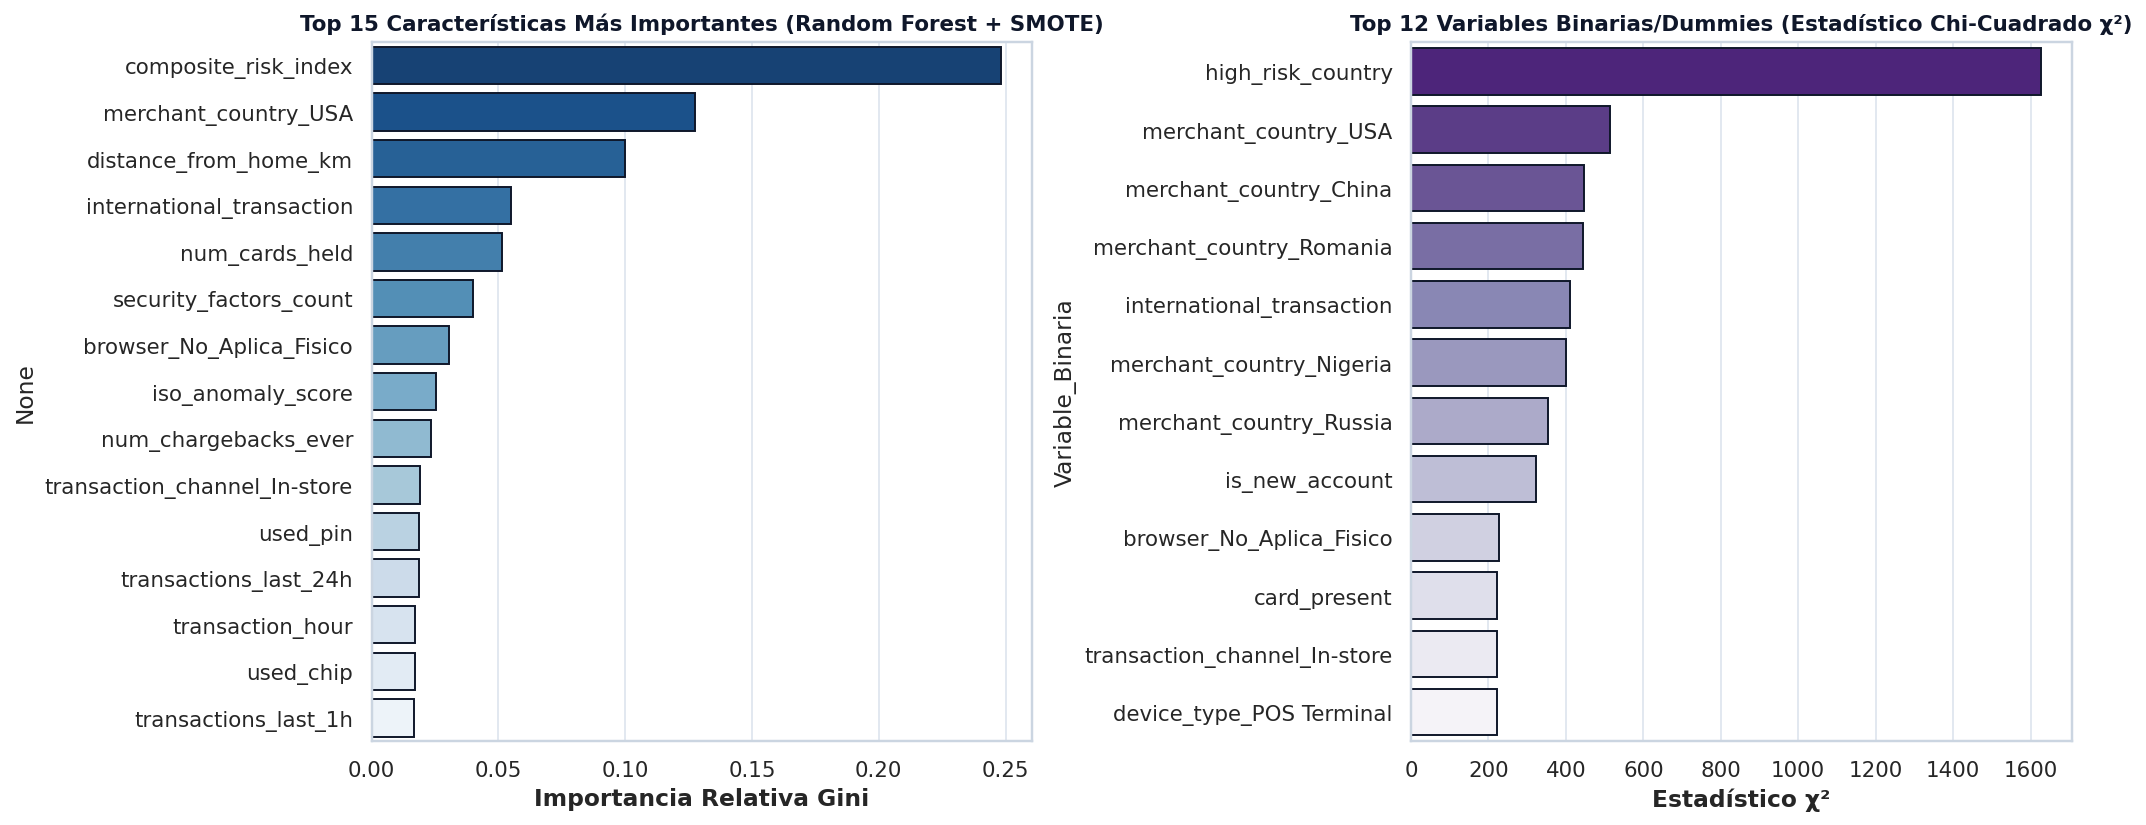

In [ ]:
# @title Etapa 7 KDD: Interpretación y Análisis: Explicación de Resultados y Relación con el Objetivo

# 7.1 Importancia de Características (Random Forest) y Top Chi-Cuadrado
rf_model = modelos['4. Random Forest (Modelo Óptimo)']
imp_series = pd.Series(rf_model.feature_importances_, index=selected_features).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.0))
sns.barplot(x=imp_series.values, y=imp_series.index, palette=sns.color_palette('Blues_r', len(imp_series)), ax=axes[0], edgecolor=CYBER_DARK)
axes[0].set_title('Top 15 Características Más Importantes (Random Forest + SMOTE)', fontweight='bold', color=CYBER_DARK)
axes[0].set_xlabel('Importancia Relativa Gini', fontweight='bold')

top_chi_plot = df_chi2.head(12)
sns.barplot(x=top_chi_plot['Chi2_Estadistico'], y=top_chi_plot['Variable_Binaria'], palette=sns.color_palette('Purples_r', len(top_chi_plot)), ax=axes[1], edgecolor=CYBER_DARK)
axes[1].set_title('Top 12 Variables Binarias/Dummies (Estadístico Chi-Cuadrado χ²)', fontweight='bold', color=CYBER_DARK)
axes[1].set_xlabel('Estadístico χ²', fontweight='bold')
plt.tight_layout()

# Exportación vectorial en formato .vsg
fig.savefig(out_dir / '03_seleccion_variables_importancia.vsg', bbox_inches='tight', format='svg')
fig.savefig(out_dir / '03_seleccion_variables_importancia.png', bbox_inches='tight', dpi=150)
print(f'[OK] Importancia de variables exportada en .vsg: {out_dir / "03_seleccion_variables_importancia.vsg"}')
plt.show()


### Interpretación de los Detonantes del Riesgo y del Árbol de Decisión
El ranking de importancia de *Random Forest* y los nodos superiores del Árbol de Decisión coinciden en que el fraude es gobernado por la interacción entre **`composite_risk_index`**, **`distance_from_home_km` (`> 544.85 km`)**, **`high_risk_country`**, **`international_transaction`**, **`iso_anomaly_score`**, **`transactions_last_1h` (`> 2.50`)** y la ausencia de seguridad física (**`security_factors_count`**, **`card_present <= 0.50`**, **`used_chip`**).

,Codigo,Regla_Decision,Transacciones_Activadas,Fraudes_Capturados,Precision_Regla_%,Lift_vs_Azar
0,R1,high_risk_country=1 & card_present=0 & tx_1h>=3,269,91,33.83,16.46
1,R2,high_risk_country=1 & account_age_days<=90,565,131,23.19,11.28
2,R3,tx_hour<=4 & international=1 & card_present=0,902,114,12.64,6.15
3,R4,amount_ratio>4.8 & chargebacks>=2 & card_prese...,611,62,10.15,4.94
4,R5,composite_risk_index >= 5 (Multiseñal),2859,575,20.11,9.79


[OK] Árbol y Lift exportados en .vsg: results/06_arbol_reglas_decision.vsg


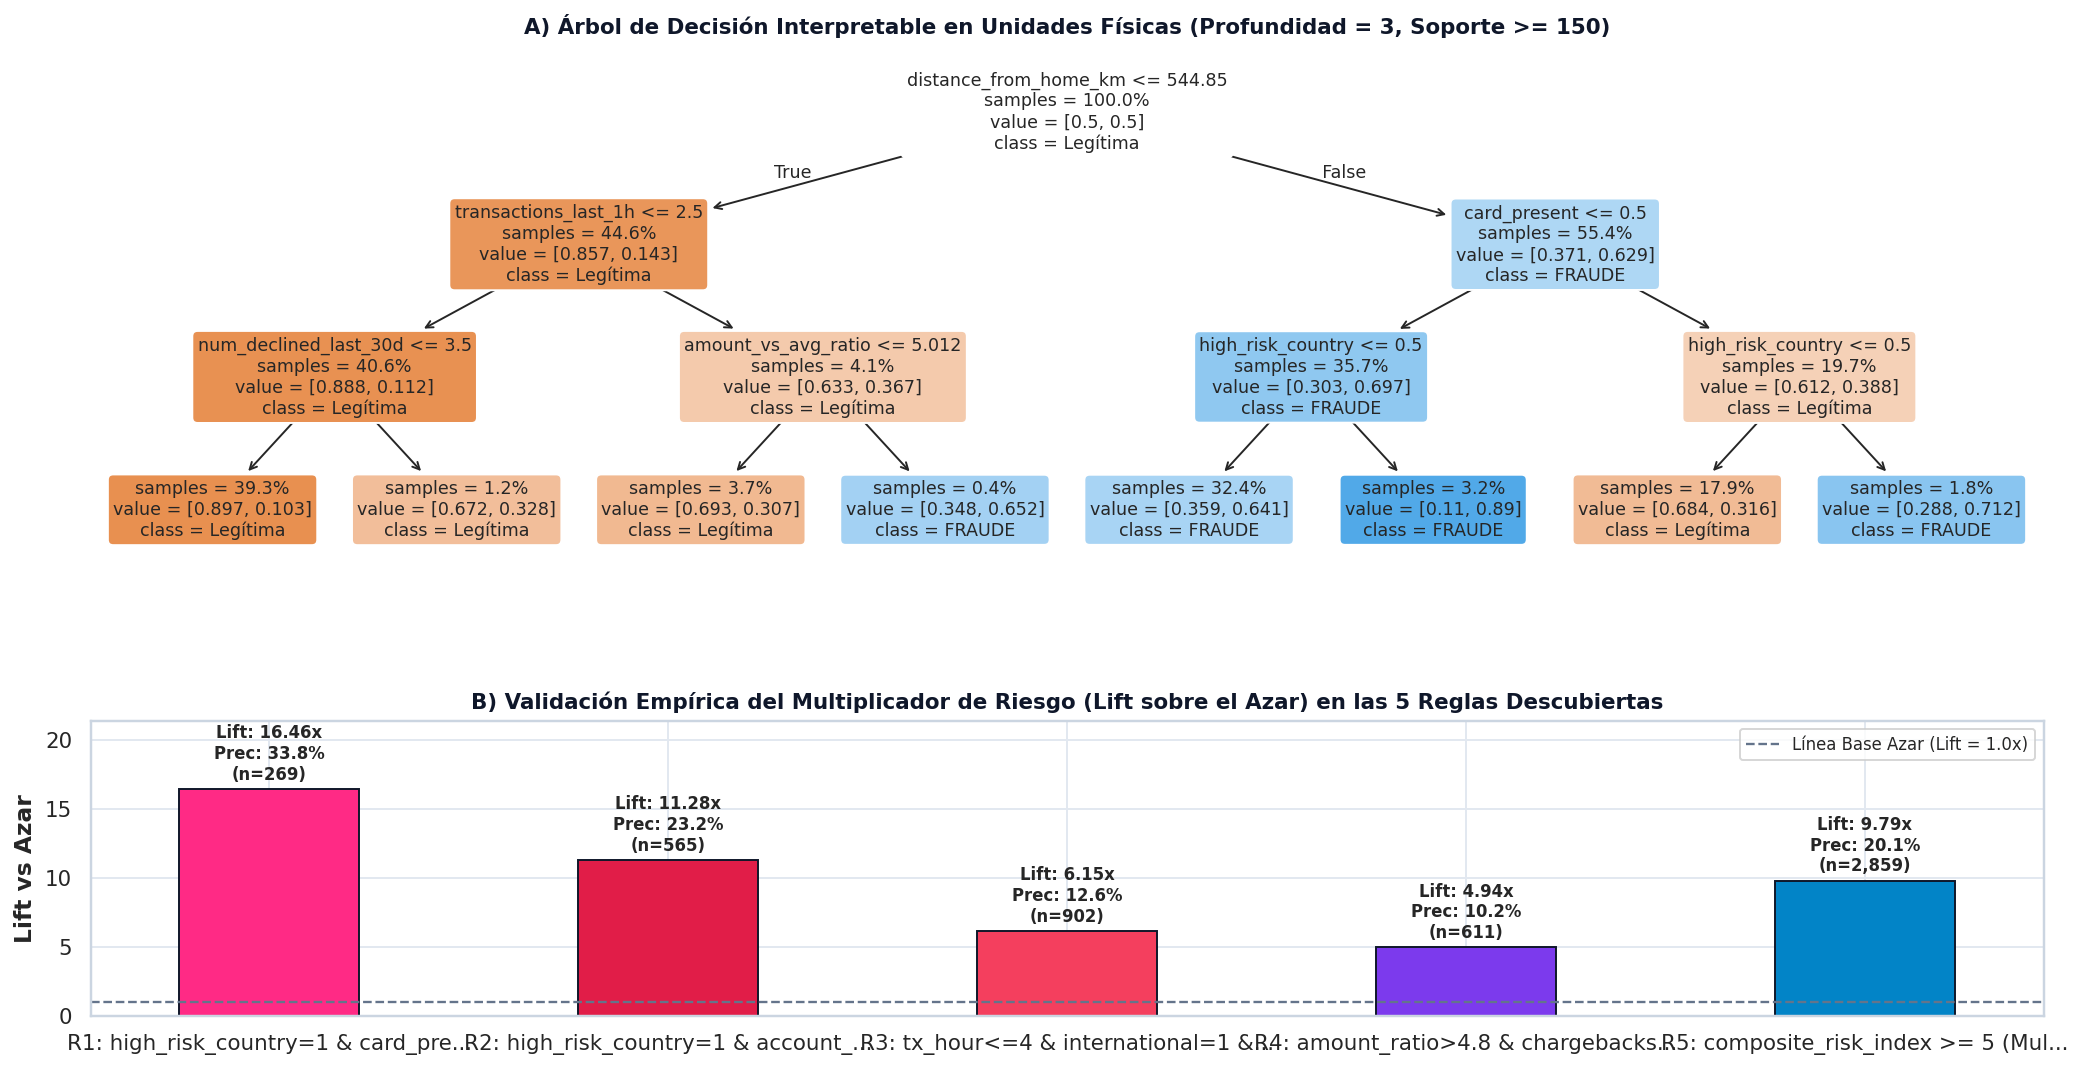

In [ ]:
# @title 7.2 Extracción de Reglas y Validación Cuantitativa del Lift de Negocio
features_reglas = [
    'high_risk_country', 'international_transaction', 'card_present', 'used_pin', 'used_chip',
    'transactions_last_1h', 'account_age_days', 'transaction_hour', 'distance_from_home_km',
    'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'num_chargebacks_ever', 'num_declined_last_30d'
]
dt_plot = DecisionTreeClassifier(max_depth=3, min_samples_leaf=150, class_weight='balanced', random_state=42)
dt_plot.fit(X_train_raw[features_reglas], y_train)

reglas_negocio = [
    ('R1', 'high_risk_country=1 & card_present=0 & tx_1h>=3', (df_raw['high_risk_country'] == 1) & (df_raw['card_present'] == 0) & (df_raw['transactions_last_1h'] >= 3)),
    ('R2', 'high_risk_country=1 & account_age_days<=90', (df_raw['high_risk_country'] == 1) & (df_raw['account_age_days'] <= 90)),
    ('R3', 'tx_hour<=4 & international=1 & card_present=0', (df_raw['transaction_hour'] <= 4) & (df_raw['international_transaction'] == 1) & (df_raw['card_present'] == 0)),
    ('R4', 'amount_ratio>4.8 & chargebacks>=2 & card_present=0', (df_raw['amount_vs_avg_ratio'] > 4.8) & (df_raw['num_chargebacks_ever'] >= 2) & (df_raw['card_present'] == 0)),
    ('R5', 'composite_risk_index >= 5 (Multiseñal)', (df_raw['composite_risk_index'] >= 5)),
]
tasa_base = df_raw['is_fraud'].mean() * 100
tabla_reglas = []
for cod_r, nombre_r, mascara in reglas_negocio:
    n_casos = int(mascara.sum())
    n_fraudes = int(df_raw.loc[mascara, 'is_fraud'].sum())
    tasa_r = (n_fraudes / n_casos * 100) if n_casos > 0 else 0.0
    lift_r = tasa_r / tasa_base
    tabla_reglas.append({
        'Codigo': cod_r,
        'Regla_Decision': nombre_r,
        'Transacciones_Activadas': n_casos,
        'Fraudes_Capturados': n_fraudes,
        'Precision_Regla_%': round(tasa_r, 2),
        'Lift_vs_Azar': round(lift_r, 2)
    })
df_reglas_val = pd.DataFrame(tabla_reglas)
df_reglas_val.to_csv(out_dir / 'reglas_negocio_validadas.csv', index=False)
display(df_reglas_val)

# Generación de la Figura 6 (Árbol y Lift en formato .vsg)
fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(2, 1, height_ratios=[1.8, 1.0], hspace=0.35)
ax_tree = fig.add_subplot(gs[0, 0])
plot_tree(dt_plot, feature_names=features_reglas, class_names=['Legítima', 'FRAUDE'], filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax_tree)
ax_tree.set_title('A) Árbol de Decisión Interpretable en Unidades Físicas (Profundidad = 3, Soporte >= 150)', fontweight='bold', color=CYBER_DARK)

ax_lift = fig.add_subplot(gs[1, 0])
bars_lift = ax_lift.bar([r['Codigo'] + ': ' + r['Regla_Decision'][:30] + '...' for r in tabla_reglas], [r['Lift_vs_Azar'] for r in tabla_reglas], color=[CYBER_MAGENTA, '#e11d48', '#f43f5e', CYBER_PURPLE, CYBER_BLUE], edgecolor=CYBER_DARK, width=0.45)
ax_lift.axhline(1.0, color='#64748b', linestyle='--', lw=1.2, label='Línea Base Azar (Lift = 1.0x)')
ax_lift.set_title('B) Validación Empírica del Multiplicador de Riesgo (Lift sobre el Azar) en las 5 Reglas Descubiertas', fontweight='bold', color=CYBER_DARK)
ax_lift.set_ylabel('Lift vs Azar', fontweight='bold')
for bar, r in zip(bars_lift, tabla_reglas):
    ax_lift.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"Lift: {r['Lift_vs_Azar']:.2f}x\nPrec: {r['Precision_Regla_%']:.1f}%\n(n={r['Transacciones_Activadas']:,})", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax_lift.set_ylim(0, max([r['Lift_vs_Azar'] for r in tabla_reglas]) * 1.3)
ax_lift.legend(loc='upper right', fontsize=8.5)
plt.tight_layout()

# Exportación vectorial en formato .vsg
fig.savefig(out_dir / '06_arbol_reglas_decision.vsg', bbox_inches='tight', format='svg')
fig.savefig(out_dir / '06_arbol_reglas_decision.png', bbox_inches='tight', dpi=150)
print(f'[OK] Árbol y Lift exportados en .vsg: {out_dir / "06_arbol_reglas_decision.vsg"}')
plt.show()


### Análisis de las Reglas de Decisión Validadas
Cada una de las 5 reglas descubiertas multiplica entre **`4.94x` y `16.46x`** la probabilidad base de fraude (`2.055%`), ofreciendo criterios transparentes que pueden programarse directamente en sistemas de autorización bancaria en tiempo real.

---
---

## Etapa 8 KDD: Conclusiones: Principales Hallazgos y Cumplimiento del Objetivo del Proyecto

### Preguntas Clave y Respuestas Fundamentadas (Q&A)

* **¿Cómo se resuelve el problema de detectar señales débiles de fraude en un dataset masivo y estadísticamente desbalanceado?** Mediante la aplicación secuencial de las 7 etapas del proceso KDD: conservando los valores atípicos legítimos y transformándolos con compresión logarítmica y escalamiento robusto, sintetizando la concurrencia de señales débiles en un índice de riesgo compuesto (`composite_risk_index`) junto con el puntaje no supervisado de *Isolation Forest* (`iso_anomaly_score`), equilibrando el espacio de entrenamiento con *SMOTE* sin contaminar el conjunto de prueba, y calibrando el umbral de decisión con métricas sensibles al costo ($F_2\text{-Score}$, *Recall* y *PR-AUC*).
* **¿Por qué no se deben eliminar los registros con valores nulos en `browser` ni los valores atípicos (*outliers*)?** Porque los `41,709` valores nulos en `browser` corresponden estructuralmente al $100\%$ de las transacciones físicas en tienda (`35,777` en `POS Terminal`) y cajeros (`5,932` en `ATM`); eliminarlos provocaría un severo sesgo de selección. Asimismo, los valores atípicos en velocidad transaccional (`transactions_last_1h > 2.5`) presentan una tasa de fraude del `5.57%` (`3.26x` mayor que el rango normal), por lo que constituyen la señal misma del fenómeno estudiado.

### Data Analysis Key Findings

* **Desbalance extremo y costo del fraude:** El conjunto de datos contiene `100,000` transacciones donde solo `2,055` (`2.055%`) son fraudulentas frente a `97,945` (`97.945%`) legítimas (razón `1 : 47.66`), acumulando una pérdida financiera de **\$279,842.20 USD** concentrada principalmente en la modalidad *Card-Not-Present* (`1,054` casos, `51.3%`).
* **Prevención de Fuga de Información (*Data Leakage*):** Se identificaron y excluyeron las variables post-evento `fraud_type` y `fraud_amount_lost`, las cuales presentaban dependencia determinista con la etiqueta objetivo, además de `6` columnas identificadoras.
* **Eficacia de la Detección de Anomalías e Ingeniería de Características:** El algoritmo no supervisado *Isolation Forest* aisló un segmento anómalo de `665` transacciones en prueba con una tasa de fraude del **`7.07%`** (**`3.75x` Lift** sobre las instancias normales), mientras que el índice compuesto `composite_risk_index >= 5` agrupó `2,859` transacciones con **`575` fraudes reales (`20.11%` de tasa de fraude, `9.79x` Lift)**.
* **Desempeño Superior de Modelos de Ensamble con *SMOTE*:** Frente al modelo *Baseline Mayoritario* (`Accuracy = 97.95%`, `Recall = 0.00%`), *Gradient Boosting + SMOTE* alcanzó el mejor poder discriminante global con **`ROC-AUC = 0.8379`** y **`PR-AUC = 0.1369`** (`167` fraudes detectados, `Recall = 40.63%`), mientras que *Random Forest + SMOTE* logró **`ROC-AUC = 0.8292`** y capturó **`220` de los `411` fraudes del conjunto de prueba (`Recall = 53.53%`)**.
* **Reglas de Decisión Accionables:** La Regla `R1` (`high_risk_country == 1` + `card_present == 0` + `transactions_last_1h >= 3`) alcanza una tasa de fraude del **`33.83%`** (**`16.46x` Lift**), y la Regla `R2` (`high_risk_country == 1` + `account_age_days <= 90`) alcanza **`23.19%`** (**`11.28x` Lift**).

### Insights or Next Steps

* **Implementación de Autenticación Escalonada (Motor Híbrido Reglas + ML):** Desplegar en producción un flujo de dos capas donde las transacciones que activen las Reglas `R1`, `R2` o `R5` reciban bloqueo preventivo inmediato, mientras que las transacciones detectadas por el umbral sensible de *Random Forest / Gradient Boosting* disparen verificación biométrica o token *3D-Secure / PIN* en tiempo real.
* **Monitoreo de Deriva de Concepto (*Concept Drift*) y Aprendizaje Continuo:** Recalibrar mensualmente los umbrales del modelo y las matrices de pesos de señales débiles incorporando la retroalimentación de contracargos confirmados para adaptarse a nuevas tácticas de fraude sintético y toma de cuentas.